# DCZ vs sham - monkey YU

Behavior of monkey YU in the sham (saline) and DCZ sessions (chemogenetic activation of the LC/NA→MCC pathway), on three levels:

- **0. Recordings**: sessions over the recording period
- **1. Execution**: reaction time, movement time
- **2. Engagement / motivation**: early touches and releases, pauses, slowing after losses, time on task
- **3. Cognitive**: performance, target selection, learning curves, switching, weight of past outcomes, model fits

Each block ends with its hypotheses and conclusions.

Statistics: sessions are the samples (one value per session, completed trials only). DCZ vs sham: two-sided Mann-Whitney U, rank-biserial r (r > 0: larger under DCZ), and the p-value of DCZ in an OLS adjusted for session date and weekday. Summary tables with Benjamini-Hochberg FDR at the end.

## Setup

In [37]:
##% imports
import itertools
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

from popy.io_tools import load_behavior
from popy.behavior_data_tools import add_switch_info, add_trial_in_block, add_date_of_recordig, drop_time_fields
from popy.config import COLORS

# output folder of the figures
os.makedirs('figs', exist_ok=True)

# fontsize 8
plt.rcParams.update({'font.size': 8})

# injection types and their colors
# the preprocessed data of YU only contains the sham and DCZ sessions (preproc_behavioral_data_yuri.py)
INJECTIONS = ['sham', 'DCZ']
INJECTION_COLORS = {'none': 'grey',          # grey
                    'DCZ': '#4CBB17',        # poison green
                    'sham': "#124BA0",       # deep blue
                    'MISSING': '#8B0000'}    # deep red

In [38]:

def pairwise_tests(sessions, y, order=INJECTIONS):
    """
    Two-sided Mann-Whitney U test of column y between every pair of injection types (sessions are the samples),
    Holm-corrected for the number of pairs. A pair is significant if the corrected p < 0.05.
    """
    rows = []
    for group_1, group_2 in itertools.combinations(order, 2):
        values_1 = sessions.loc[sessions.injection == group_1, y]
        values_2 = sessions.loc[sessions.injection == group_2, y]
        u, p = stats.mannwhitneyu(values_1, values_2, alternative='two-sided')
        rows.append({'group_1': group_1, 'group_2': group_2, 'n_1': len(values_1), 'n_2': len(values_2), 'U': u, 'p': p})

    stats_df = pd.DataFrame(rows)
    stats_df['significant'], stats_df['p_holm'] = multipletests(stats_df['p'], alpha=0.05, method='holm')[:2]

    return stats_df


def plot_box_with_scatter(sessions, y, ax, order=INJECTIONS):
    """
    Boxplot of column y per injection type, with the sessions as scatter points slightly left of the boxes.
    """
    sns.boxplot(data=sessions, x='injection', y=y, order=order,
                hue='injection', hue_order=order, palette=INJECTION_COLORS, legend=False,
                width=0.3, ax=ax,
                boxprops=dict(alpha=0.5, edgecolor='black', linewidth=1.5),
                whiskerprops=dict(color='black', linewidth=1.5),
                capprops=dict(color='black', linewidth=1.5),
                medianprops=dict(color='black', linewidth=1.5),
                showfliers=False)

    # add scatter points slightly to the left of the box
    strip = sns.stripplot(data=sessions, x='injection', y=y, order=order,
                          hue='injection', hue_order=order, palette=INJECTION_COLORS, legend=False,
                          alpha=0.6, size=3, ax=ax, jitter=0.1, zorder=0)

    # shift stripplot points to the left
    for collection in strip.collections:
        offsets = collection.get_offsets()
        offsets[:, 0] = offsets[:, 0] - 0.2  # shift left
        collection.set_offsets(offsets)

    # formatting, with number of sessions per injection type in the tick labels
    n_sessions = sessions.injection.value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f'{injection}\n(n={n_sessions.get(injection, 0)})' for injection in order])
    ax.set_xlabel('')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)


def draw_bracket(ax, x1, x2, y, height, p):
    """
    Draws a significance bracket between x1 and x2 at height y, with stars for the p-value.
    """
    ax.plot([x1, x1, x2, x2], [y - height / 4, y, y, y - height / 4], color='black', linewidth=0.8)
    stars = '***' if p < .001 else '**' if p < .01 else '*'
    ax.text((x1 + x2) / 2, y - height / 8, stars, ha='center', va='bottom')


def add_significance_bars(ax, stats_df, values, order=INJECTIONS):
    """
    Draws a bracket with stars above the boxes for every significant pair (Holm-corrected p < 0.05),
    shorter brackets lower.
    """
    significant = stats_df[stats_df['significant']].copy()
    if significant.empty:
        ax.text(0.5, 1.0, 'all pairs n.s.', transform=ax.transAxes, ha='center', va='bottom')
        return

    significant['x1'] = significant['group_1'].apply(order.index)
    significant['x2'] = significant['group_2'].apply(order.index)
    significant['width'] = significant['x2'] - significant['x1']
    significant = significant.sort_values(['width', 'x1'])

    step = 0.12 * (values.max() - values.min())
    for level, (_, row) in enumerate(significant.iterrows(), start=1):
        draw_bracket(ax, row['x1'], row['x2'], values.max() + level * step, step, row['p_holm'])


def compare_injections(sessions, measures, ncols=4, order=INJECTIONS):
    """
    One boxplot panel per measure ({column of sessions: y label}), with pairwise tests between the injection types.
    Measures that are 0 in every session are only plotted, not tested.
    Returns the figure and the Holm-corrected p-values (rows: pairs of injection types, columns: measures).
    """
    nrows = int(np.ceil(len(measures) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.4 * nrows), squeeze=False)

    p_holm = {}
    for ax, (measure, ylabel) in zip(axs.flat, measures.items()):
        plot_box_with_scatter(sessions, measure, ax, order=order)
        ax.set_ylabel(ylabel)
        if (sessions[measure] == 0).all():
            ax.text(0.5, 1.0, 'never occurs', transform=ax.transAxes, ha='center', va='bottom')
            continue
        stats_df = pairwise_tests(sessions, measure, order=order)
        add_significance_bars(ax, stats_df, sessions[measure], order=order)
        p_holm[measure] = stats_df.set_index(['group_1', 'group_2'])['p_holm']

    # hide unused panels
    for ax in axs.flat[len(measures):]:
        ax.set_visible(False)
    plt.tight_layout()

    return fig, pd.DataFrame(p_holm)


def format_date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%y'))
    for tick in ax.get_xticklabels():
        tick.set_rotation(20)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

In [39]:
# (6) helpers
import statsmodels.formula.api as smf
from scipy import optimize
import os
import sys
import popy
import popy.config as cfg
from popy.io_tools_helpers import reformat_behav

sys.path.append(os.path.join(os.path.dirname(popy.__file__), '..', 'notebooks', 'preprocessing_sessions', 'preproc_behavioral_data'))
from fix_events_yuri import load_events_yuri, fix_events_yuri

DCZ_ORDER = INJECTIONS
DCZ_RESULTS = {}                     # DCZ vs sham tests, {(hypothesis, measure): result}, for the summary table


def load_raw_events(session, injection):
    '''
    Raw events (code, time) of one session, from the same npz file and with the same event fixes as the
    preprocessing (preproc_behavioral_data_yuri.py).
    '''
    events, _ = fix_events_yuri(load_events_yuri(os.path.join(cfg.COMBINED_DATA_PATH, injection, f'{session}_events.npz')))
    return events[['code', 'time']].to_numpy(dtype=float)


def get_trial_timing(session, injection):
    '''
    Event times that the preprocessing does not keep, from the raw events of one session. Per trial: lever available
    (first 60), first lever touch (first 61), first target touch after the lever release, target release after the target validation (first 137/138/144 after
    the 125). Per lever touch: the hold
    duration, until the release before validation (61 -> 63) or the release after validation (61 -> 62 -> 64).
    '''
    raw = load_raw_events(session, injection)
    trials, holds = [], []
    for trial_events in reformat_behav(raw)['behav_events']:
        codes, times = trial_events[:, 0].astype(int), trial_events[:, 1]
        start = round(times[0], 4)
        i_release = np.argmax(codes == 64) if (codes == 64).any() else len(codes)
        is_target_touch_after_release = np.isin(codes, [121, 122, 123]) & (np.arange(len(codes)) > i_release)
        i_target_validation = np.argmax(codes == 125) if (codes == 125).any() else len(codes)
        is_target_release = np.isin(codes, [137, 138, 144]) & (np.arange(len(codes)) > i_target_validation)
        trials.append({'session': session, 'trial_start_time': start,
                       'lever_on_time': times[np.argmax(codes == 60)] if (codes == 60).any() else np.nan,
                       'first_lever_touch_time': times[np.argmax(codes == 61)] if (codes == 61).any() else np.nan,
                       'first_target_touch_time': times[np.argmax(is_target_touch_after_release)] if is_target_touch_after_release.any() else np.nan,
                       'target_release_time': times[np.argmax(is_target_release)] if is_target_release.any() else np.nan})
        for i in np.where(codes[:-1] == 61)[0]:
            if codes[i + 1] == 63:
                holds.append({'session': session, 'trial_start_time': start, 'hold': times[i + 1] - times[i], 'validated': False})
            elif codes[i + 1] == 62 and (codes[i + 1:] == 64).any():
                i_64 = i + 1 + np.argmax(codes[i + 1:] == 64)
                holds.append({'session': session, 'trial_start_time': start, 'hold': times[i_64] - times[i], 'validated': True})
    return pd.DataFrame(trials), pd.DataFrame(holds)


def dcz_test(sessions, measure):
    '''
    DCZ vs sham sessions: two-sided Mann-Whitney U test and rank-biserial correlation (r > 0: larger under DCZ), and
    the p-value of DCZ in an OLS adjusted for the session date and weekday (sham and DCZ sessions only).
    '''
    values = sessions.dropna(subset=[measure])
    DCZ, sham = values.loc[values.injection == 'DCZ', measure], values.loc[values.injection == 'sham', measure]
    u, p = stats.mannwhitneyu(DCZ, sham, alternative='two-sided')
    data = values[values.injection.isin(['sham', 'DCZ'])].assign(is_dcz=lambda df: (df.injection == 'DCZ').astype(float))
    ols = smf.ols(f'{measure} ~ is_dcz + days + weekday', data=data).fit()
    return {'measure': measure, 'median_sham': sham.median(), 'median_dcz': DCZ.median(),
            'r': 2 * u / (len(DCZ) * len(sham)) - 1, 'p': p, 'p_adjusted_ols': ols.pvalues['is_dcz']}


def plot_dcz_panel(ax, sessions, measure, ylabel, hypothesis):
    '''
    Boxplot of a session measure (sham, DCZ), titled with the DCZ vs sham test, which is stored in DCZ_RESULTS.
    '''
    plot_box_with_scatter(sessions, measure, ax, order=DCZ_ORDER)
    result = dcz_test(sessions, measure)
    DCZ_RESULTS[(hypothesis, measure)] = result
    ax.set_ylabel(ylabel)
    ax.set_title(f'{hypothesis}: DCZ vs sham p={result["p"]:.2g}, r={result["r"]:+.2f}', fontsize=7)
    return result


def plot_condition_lines(ax, data, x, y, label_suffix=''):
    '''
    Mean ± SEM over sessions of y as a function of x, one line per condition (data: one row per session and x).
    '''
    for injection in DCZ_ORDER:
        stats_x = data[data.injection == injection].groupby(x)[y].agg(['mean', 'sem'])
        ax.plot(stats_x.index, stats_x['mean'], color=INJECTION_COLORS[injection], label=f'{injection}{label_suffix}')
        ax.fill_between(stats_x.index, stats_x['mean'] - stats_x['sem'], stats_x['mean'] + stats_x['sem'],
                        color=INJECTION_COLORS[injection], alpha=0.2, linewidth=0)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

In [40]:
# load all sessions of monkey yu
behav = load_behavior('yu')
behav

,monkey,injection,session,trial_id,trial_start_time,n_target_touches,lever_touch_time,lever_validation_time,lever_release_time,target_touch_time,...,target,feedback,n_events,n_early_lever_release,n_late_lever_touch,n_premature_target_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward,n_false_touch
8790,yu,sham,010224,0,406.6467,1.0,408.4805,410.0001,410.6925,411.0273,...,3.0,1.0,14,0,0,0,0,0,0,0
8791,yu,sham,010224,1,413.0286,1.0,413.3798,414.9007,415.6568,415.8628,...,3.0,0.0,13,0,0,0,0,0,0,0
8792,yu,sham,010224,2,417.8087,1.0,426.7609,428.2762,429.3186,429.5576,...,3.0,0.0,29,2,0,2,0,0,1,5
8793,yu,sham,010224,3,431.5503,1.0,432.8637,434.3738,435.8459,436.0895,...,3.0,1.0,19,0,0,1,0,1,0,2
8794,yu,sham,010224,4,438.2179,1.0,438.5759,440.0940,440.8073,441.0272,...,3.0,0.0,20,0,0,0,0,0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20361,yu,sham,311023,601,6217.0367,2.0,6222.9790,6224.4904,6224.7375,6225.7623,...,3.0,1.0,34,6,0,0,1,0,0,7
20362,yu,sham,311023,602,6227.7006,1.0,6227.9874,6229.5040,6229.8453,6230.0463,...,3.0,0.0,17,0,0,0,0,0,1,1
20363,yu,sham,311023,603,6232.0158,1.0,6232.3439,6233.8539,6234.1947,6234.4082,...,3.0,1.0,20,0,0,1,0,1,0,2
20364,yu,sham,311023,604,6236.3478,1.0,6243.8547,6245.3652,6245.7283,6245.9409,...,3.0,1.0,30,5,0,0,0,1,0,6


In [41]:
print(f"num sessions dcz: {len(behav[behav.injection == 'DCZ'].session.unique())}")
print(f"num sessions sham: {len(behav[behav.injection == 'sham'].session.unique())}")

num sessions dcz: 16
num sessions sham: 21


In [42]:

behav = add_switch_info(behav)
behav = add_trial_in_block(behav)
behav = add_date_of_recordig(behav)
behav['if_best_target'] = behav['target'] == behav['best_target']

#behav = drop_time_fields(behav)
behav = behav.dropna()

behav

,date_of_recording,monkey,injection,session,trial_id,trial_start_time,n_target_touches,lever_touch_time,lever_validation_time,lever_release_time,...,n_early_lever_release,n_late_lever_touch,n_premature_target_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward,n_false_touch,switch,trial_id_in_block,if_best_target
1,2024-02-01,yu,sham,010224,1,413.0286,1.0,413.3798,414.9007,415.6568,...,0,0,0,0,0,0,0,0.0,1,False
2,2024-02-01,yu,sham,010224,2,417.8087,1.0,426.7609,428.2762,429.3186,...,2,0,2,0,0,1,5,0.0,2,False
3,2024-02-01,yu,sham,010224,3,431.5503,1.0,432.8637,434.3738,435.8459,...,0,0,1,0,1,0,2,0.0,3,False
4,2024-02-01,yu,sham,010224,4,438.2179,1.0,438.5759,440.0940,440.8073,...,0,0,0,0,0,2,2,0.0,4,False
5,2024-02-01,yu,sham,010224,5,443.0217,1.0,444.3109,445.8194,446.9710,...,0,0,2,0,0,0,2,0.0,5,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20361,2023-10-31,yu,sham,311023,601,6217.0367,2.0,6222.9790,6224.4904,6224.7375,...,6,0,0,1,0,0,7,0.0,38,True
20362,2023-10-31,yu,sham,311023,602,6227.7006,1.0,6227.9874,6229.5040,6229.8453,...,0,0,0,0,0,1,1,0.0,39,True
20363,2023-10-31,yu,sham,311023,603,6232.0158,1.0,6232.3439,6233.8539,6234.1947,...,0,0,1,0,1,0,2,0.0,40,True
20364,2023-10-31,yu,sham,311023,604,6236.3478,1.0,6243.8547,6245.3652,6245.7283,...,5,0,0,0,1,0,6,0.0,41,True


In [43]:
# one row per session
sessions = behav.groupby('session').agg(
    date=('date_of_recording', 'first'),
    injection=('injection', 'first'),
    n_switches=('switch', 'sum'),
    reward_rate=('feedback', 'mean'),
    p_best_target=('if_best_target', 'mean'),
).sort_values('date')

# rate of selecting each target
for target in [1, 2, 3]:
    sessions[f'selection_target_{target}'] = (behav['target'] == target).groupby(behav['session']).mean()

# mean number of events and false touches per trial
touch_columns = ['n_events', 'n_early_lever_release', 'n_late_lever_touch', 'n_early_target_release']
sessions = sessions.join(behav.groupby('session')[touch_columns].mean())

# late target touches after reward / after no reward: mean per rewarded / not rewarded trial
sessions['n_late_target_touch_after_reward'] = behav[behav['feedback'] == 1].groupby('session')['n_late_target_touch_after_reward'].mean()
sessions['n_late_target_touch_after_no_reward'] = behav[behav['feedback'] == 0].groupby('session')['n_late_target_touch_after_no_reward'].mean()

sessions

,date,injection,n_switches,reward_rate,p_best_target,selection_target_1,selection_target_2,selection_target_3,n_events,n_early_lever_release,n_late_lever_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward
session,,,,,,,,,,,,,,
270923,2023-09-27,DCZ,81.0,0.604356,0.720508,0.166969,0.317604,0.515426,21.313975,1.012704,0.0,0.370236,0.408408,0.559633
231023,2023-10-23,sham,81.0,0.632058,0.766849,0.222222,0.387978,0.389800,18.595628,0.451730,0.0,0.387978,0.317003,0.386139
241023,2023-10-24,DCZ,82.0,0.612022,0.737705,0.151184,0.380692,0.468124,22.191257,0.936248,0.0,0.617486,0.288690,0.488263
251023,2023-10-25,sham,85.0,0.597270,0.699659,0.124573,0.481229,0.394198,19.406143,0.508532,0.0,0.663823,0.408571,0.550847
261023,2023-10-26,DCZ,120.0,0.553090,0.622821,0.104596,0.451664,0.443740,24.285261,1.419968,0.0,0.553090,0.326648,0.343972
311023,2023-10-31,sham,100.0,0.574614,0.696398,0.135506,0.377358,0.487136,20.511149,0.799314,0.0,0.308748,0.567164,0.584677
071123,2023-11-07,sham,84.0,0.635701,0.797814,0.251366,0.357013,0.391621,19.154827,0.489982,0.0,0.533698,0.492837,0.590000
081123,2023-11-08,DCZ,54.0,0.621572,0.762340,0.193784,0.431444,0.374771,21.886654,1.001828,0.0,0.672761,0.320588,0.415459
141123,2023-11-14,sham,57.0,0.670611,0.785010,0.209073,0.390533,0.400394,20.132150,0.830375,0.0,0.388560,0.370588,0.532934


In [44]:
# trial-level data: completed trials of the sham and DCZ sessions (interrupted trials excluded, as in the
# foraging paper), switches relative to the previous completed trial
dcz_trials = load_behavior('yu')
dcz_trials = dcz_trials[dcz_trials.injection.isin(DCZ_ORDER) & dcz_trials.target.notna()]
dcz_trials = add_trial_in_block(add_switch_info(dcz_trials))

# event timings and lever holds from the raw events (~30 s)
timing, holds = map(pd.concat, zip(*[get_trial_timing(session, injection) for session, injection in dcz_trials.groupby('session')['injection'].first().items()]))
dcz_trials['trial_start_time'] = dcz_trials['trial_start_time'].round(4)
dcz_trials = dcz_trials.merge(timing, on=['session', 'trial_start_time'], how='left', validate='one_to_one')
dcz_holds = holds.merge(dcz_trials[['session', 'trial_start_time', 'injection']], on=['session', 'trial_start_time'])  # holds of the analysed trials

# trial measures
dcz_trials['log_rt'] = np.log((dcz_trials['lever_release_time'] - dcz_trials['lever_validation_time']) * 1000)  # RT, as in (4)
dcz_trials['log_mt'] = np.log((dcz_trials['first_target_touch_time'] - dcz_trials['lever_release_time']) * 1000)  # movement time
dcz_trials['initiation'] = dcz_trials['first_lever_touch_time'] - dcz_trials['lever_on_time']  # lever available -> first touch
dcz_trials['log_initiation'] = np.log(dcz_trials['initiation'] * 1000)
dcz_trials['log_target_hold'] = np.log((dcz_trials['target_release_time'] - dcz_trials['target_validation_time']) * 1000)  # target validation -> release
dcz_trials['trial_length'] = dcz_trials['trial_end_time'] - dcz_trials['trial_start_time']  # trial start (100) -> trial end (101), s
dcz_trials['pause'] = (dcz_trials['initiation'] > 5).astype(float)  # more than 5 s before touching the lever
dcz_trials['best'] = (dcz_trials['target'] == dcz_trials['best_target']).astype(float)
dcz_trials['prev_feedback'] = dcz_trials.groupby('session')['feedback'].shift(1)
dcz_trials['session_fraction'] = dcz_trials.groupby('session').cumcount() / dcz_trials.groupby('session')['session'].transform('size')
dcz_trials['session_quarter'] = np.minimum((dcz_trials['session_fraction'] * 4).astype(int), 3) + 1


def release_hazard(holds, start, stop):
    '''P(lever released before validation within [start, stop) s of holding | held until start).'''
    at_risk = holds['hold'] >= start
    return (at_risk & (holds['hold'] < stop) & ~holds['validated']).sum() / at_risk.sum()


# one row per session
by_session = dcz_trials.groupby('session')
dcz_sessions = pd.DataFrame({
    'injection': by_session['injection'].first(),
    'date': pd.to_datetime(by_session['session'].first(), format='%d%m%y'),
    'log_rt': by_session['log_rt'].median(),
    'log_mt': by_session['log_mt'].median(),
    'log_initiation': by_session['log_initiation'].median(),
    'pause_rate': by_session['pause'].mean(),
    'trials_per_min': by_session.size() / ((by_session['trial_end_time'].max() - by_session['trial_start_time'].min()) / 60),
    'p_best': by_session['best'].mean(),
    'reward_rate': by_session['feedback'].mean(),
})
dcz_sessions['days'] = (dcz_sessions['date'] - dcz_sessions['date'].min()).dt.days
dcz_sessions['weekday'] = dcz_sessions['date'].dt.dayofweek
by_session_holds = dcz_holds.groupby('session')
dcz_sessions['slip_hazard'] = by_session_holds.apply(release_hazard, 0, 0.25)          # release in the first 250 ms
dcz_sessions['late_release_hazard'] = by_session_holds.apply(release_hazard, 1.0, 1.5)  # release in the last 500 ms before validation
dcz_sessions['early_lever_release'] = by_session['n_early_lever_release'].mean()

print(dcz_sessions.groupby('injection').size().loc[DCZ_ORDER].to_string())
dcz_sessions.head()

/home/uzsombi/miniconda3/envs/popy_local/lib/python3.10/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


injection
sham    21
DCZ     16


,injection,date,log_rt,log_mt,log_initiation,pause_rate,trials_per_min,p_best,reward_rate,days,weekday,slip_hazard,late_release_hazard,early_lever_release
session,,,,,,,,,,,,,,
010224,sham,2024-02-01,6.200001,5.405152,5.680204,0.009804,9.825427,0.798039,0.645669,127,3,0.246452,0.051852,0.519608
011223,DCZ,2023-12-01,5.429344,5.338659,5.160365,0.000000,9.963278,0.803922,0.656863,65,4,0.241201,0.236390,0.894118
070224,DCZ,2024-02-07,5.553534,5.451968,5.370638,0.003922,9.833577,0.864706,0.684314,133,2,0.210466,0.193548,0.723529
071123,sham,2023-11-07,6.008567,5.499352,5.313370,0.019892,7.715921,0.795660,0.632911,41,1,0.202916,0.103226,0.493671
071223,sham,2023-12-07,6.021508,5.459869,5.221346,0.008418,8.032069,0.678451,0.567340,71,3,0.224886,0.070093,0.474747


In [45]:
# (7) helpers: tests of the original hypotheses, collected separately from (6)
import statsmodels.api as sm
from sklearn.mixture import GaussianMixture

ORIGINAL_RESULTS = {}  # {(hypothesis, measure): {'test', 'values', 'effect', 'p'}}


def plot_original_panel(ax, sessions, measure, ylabel, hypothesis, fmt='{:.3g}'):
    '''Boxplot of a session measure (sham, DCZ) with the DCZ vs sham test, stored in ORIGINAL_RESULTS.'''
    plot_box_with_scatter(sessions, measure, ax, order=DCZ_ORDER)
    result = dcz_test(sessions, measure)
    ORIGINAL_RESULTS[(hypothesis, measure)] = {
        'test': 'DCZ vs sham, Mann-Whitney U (r)', 'effect': result['r'], 'p': result['p'],
        'values': f'sham {fmt.format(result["median_sham"])} → DCZ {fmt.format(result["median_dcz"])}'}
    ax.set_ylabel(ylabel)
    ax.set_title(f'{hypothesis}: DCZ vs sham p={result["p"]:.2g}, r={result["r"]:+.2f}', fontsize=7)
    return result


dcz_trials['rt_ms'] = np.exp(dcz_trials['log_rt'])

## 0. Recordings

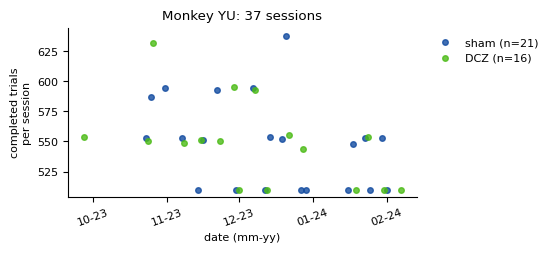

           count   mean   std    min    25%    50%    75%    max
injection                                                       
sham        21.0  548.0  37.0  510.0  510.0  552.0  554.0  638.0
DCZ         16.0  549.0  35.0  510.0  510.0  550.0  554.0  632.0


In [46]:
# length of the sessions (completed trials) over the recording period
n_trials = dcz_trials.groupby('session').size()

fig, ax = plt.subplots(1, 1, figsize=(4.5, 2.2))
for injection in INJECTIONS:
    session_inj = dcz_sessions[dcz_sessions.injection == injection]
    ax.plot(session_inj['date'], n_trials.loc[session_inj.index], 'o', color=INJECTION_COLORS[injection], markersize=4,
            alpha=.8, label=f'{injection} (n={len(session_inj)})')
ax.set_title(f'Monkey YU: {len(dcz_sessions)} sessions')
ax.set_ylabel('completed trials\nper session')
ax.set_xlabel('date (mm-yy)')
format_date_axis(ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.savefig('figs/yu_sessions_over_time.svg', dpi=300, bbox_inches='tight')
plt.show()

print(n_trials.groupby(dcz_sessions['injection']).describe().loc[INJECTIONS].round(0).to_string())

## 1. Execution level

Reaction time (RT): lever validation (62) → lever release (64), log-transformed (ln ms). Movement time: lever release → first target touch.

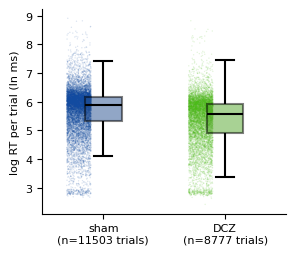

RT per trial, median (ms): {'sham': 355.0, 'DCZ': 262.0}


In [47]:
# log RT of every trial, per condition (the test is done on the session medians, next cell)
trial_rts = dcz_trials[np.isfinite(dcz_trials['log_rt'])]

fig, ax = plt.subplots(1, 1, figsize=(3, 2.6))
plot_box_with_scatter(trial_rts, 'log_rt', ax)
for collection in ax.collections:  # many points: smaller and more transparent
    collection.set_sizes([1])
    collection.set_alpha(0.15)
ax.set_xticks(range(len(INJECTIONS)), [f'{injection}\n(n={(trial_rts.injection == injection).sum()} trials)' for injection in INJECTIONS])
ax.set_ylabel('log RT per trial (ln ms)')
plt.tight_layout()
plt.savefig('figs/yu_rt_all_trials.svg', dpi=300)
plt.show()

print('RT per trial, median (ms):', np.exp(trial_rts.groupby('injection')['log_rt'].median()).loc[INJECTIONS].round(0).to_dict())

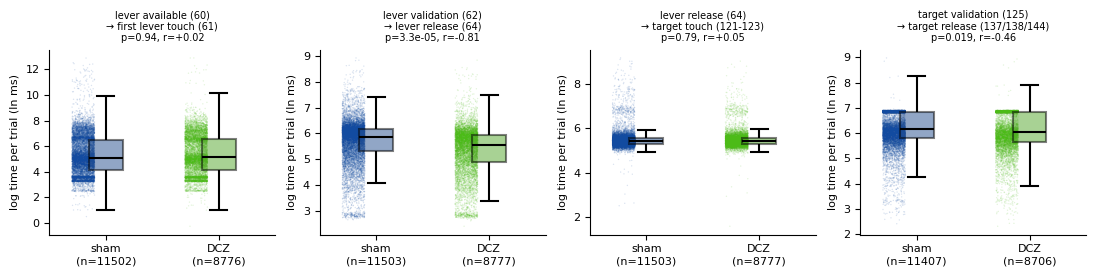

median of the session medians, DCZ vs sham (n = trials in the tick labels):
                                              interval  sham (ms)  DCZ (ms)      r        p  p_adjusted_ols
         lever available (60) → first lever touch (61)        178       166 0.0179    0.939           0.597
            lever validation (62) → lever release (64)        353       255  -0.81 3.27e-05        4.94e-08
           lever release (64) → target touch (121-123)        227       230 0.0536    0.794           0.818
target validation (125) → target release (137/138/144)        488       416 -0.458    0.019           0.101


In [48]:
# the four intervals of a trial, every trial (log ms), per condition. DCZ vs sham test on the session medians
# (Mann-Whitney U, rank-biserial r), in the panel titles
INTERVALS = {'log_initiation': 'lever available (60)\n→ first lever touch (61)',
             'log_rt': 'lever validation (62)\n→ lever release (64)',
             'log_mt': 'lever release (64)\n→ target touch (121-123)',
             'log_target_hold': 'target validation (125)\n→ target release (137/138/144)'}

fig, axs = plt.subplots(1, 4, figsize=(11, 2.8))
interval_results = []
for ax, (measure, title) in zip(axs, INTERVALS.items()):
    trial_values = dcz_trials[np.isfinite(dcz_trials[measure])]
    plot_box_with_scatter(trial_values, measure, ax)
    for collection in ax.collections:  # many points: smaller and more transparent
        collection.set_sizes([1])
        collection.set_alpha(0.15)
    ax.set_xticks(range(len(INJECTIONS)), [f'{injection}\n(n={(trial_values.injection == injection).sum()})' for injection in INJECTIONS])
    session_medians = trial_values.groupby('session').agg(injection=('injection', 'first'), value=(measure, 'median'))
    session_medians = session_medians.join(dcz_sessions[['days', 'weekday']]).rename(columns={'value': measure})
    result = dcz_test(session_medians, measure)
    interval_results.append({'interval': title.replace('\n', ' '), 'sham (ms)': np.exp(result['median_sham']),
                             'DCZ (ms)': np.exp(result['median_dcz']), 'r': result['r'], 'p': result['p'],
                             'p_adjusted_ols': result['p_adjusted_ols']})
    ax.set_title(f'{title}\np={result["p"]:.2g}, r={result["r"]:+.2f}', fontsize=7)
    ax.set_ylabel('log time per trial (ln ms)')
plt.tight_layout()
plt.savefig('figs/yu_trial_intervals.svg', dpi=300)
plt.show()

print('median of the session medians, DCZ vs sham (n = trials in the tick labels):')
print(pd.DataFrame(interval_results).to_string(index=False, float_format='{:.3g}'.format))

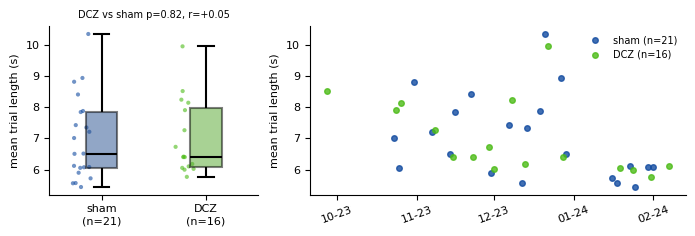

mean trial length (s), median over sessions: {'sham': 6.51, 'DCZ': 6.41}


In [49]:
# average trial length (trial start 100 -> trial end 101) per session: per condition and over the recording period
dcz_sessions['trial_length'] = dcz_trials.groupby('session')['trial_length'].mean()

fig, axs = plt.subplots(1, 2, figsize=(7, 2.4), gridspec_kw={'width_ratios': [1, 1.8]})
plot_box_with_scatter(dcz_sessions, 'trial_length', axs[0])  # descriptive, not in the summary of the hypotheses
result = dcz_test(dcz_sessions, 'trial_length')
axs[0].set_title(f'DCZ vs sham p={result["p"]:.2g}, r={result["r"]:+.2f}', fontsize=7)
axs[0].set_ylabel('mean trial length (s)')
ax = axs[1]
for injection in INJECTIONS:
    session_inj = dcz_sessions[dcz_sessions.injection == injection]
    ax.plot(session_inj['date'], session_inj['trial_length'], 'o', color=INJECTION_COLORS[injection], markersize=4, alpha=.8,
            label=f'{injection} (n={len(session_inj)})')
ax.set_ylabel('mean trial length (s)')
format_date_axis(ax)
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_trial_length.svg', dpi=300)
plt.show()

print('mean trial length (s), median over sessions:', dcz_sessions.groupby('injection')['trial_length'].median().loc[INJECTIONS].round(2).to_dict())

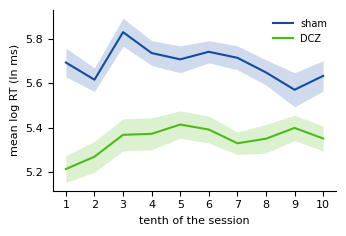

mean RT per bin (ms), mean over sessions:
session_bin     1      2      3      4      5      6      7      8      9      10
injection                                                                        
sham         297.0  275.0  340.0  309.0  301.0  311.0  303.0  284.0  262.0  279.0
DCZ          184.0  194.0  214.0  215.0  225.0  220.0  206.0  211.0  221.0  211.0
DCZ vs sham p per bin: [0.0, 0.001, 0.0002, 0.0006, 0.0025, 0.0002, 0.0001, 0.0031, 0.0446, 0.008]


In [50]:
# mean log RT across the session: session divided in 10 bins of trials (as for the early lever releases in level 2)
dcz_trials['session_bin'] = np.minimum((dcz_trials['session_fraction'] * 10).astype(int), 9) + 1
rt_bins = dcz_trials[np.isfinite(dcz_trials['log_rt'])].groupby(['session', 'session_bin']).agg(
    injection=('injection', 'first'), log_rt=('log_rt', 'mean')).reset_index()

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.4))
plot_condition_lines(ax, rt_bins, 'session_bin', 'log_rt')
ax.set_xticks(range(1, 11))
ax.set_xlabel('tenth of the session')
ax.set_ylabel('mean log RT (ln ms)')
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_rt_over_session.svg', dpi=300)
plt.show()

# DCZ vs sham per bin (Mann-Whitney U over sessions, uncorrected)
p_bins = [stats.mannwhitneyu(*(values.loc[values.injection == injection, 'log_rt'] for injection in ('DCZ', 'sham'))).pvalue
          for _, values in rt_bins.groupby('session_bin')]
print('mean RT per bin (ms), mean over sessions:')
print(np.exp(rt_bins.groupby(['injection', 'session_bin'])['log_rt'].mean().unstack()).loc[INJECTIONS].round(0).to_string())
print('DCZ vs sham p per bin:', np.round(p_bins, 4).tolist())

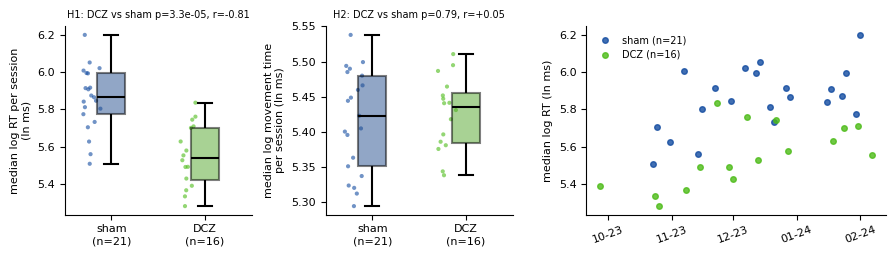

H1 log_rt: median sham 353 ms, DCZ 255 ms | p=3.3e-05, r=-0.81, adjusted OLS p=4.9e-08
H2 log_mt: median sham 227 ms, DCZ 230 ms | p=0.79, r=+0.05, adjusted OLS p=0.82


In [51]:
# H1: RT (lever validation -> release), H2: movement time (release -> first target touch)
fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), gridspec_kw={'width_ratios': [1, 1, 1.6]})
plot_dcz_panel(axs[0], dcz_sessions, 'log_rt', 'median log RT per session\n(ln ms)', 'H1')
plot_dcz_panel(axs[1], dcz_sessions, 'log_mt', 'median log movement time\nper session (ln ms)', 'H2')

# session RT across the recording period
ax = axs[2]
for injection in DCZ_ORDER:
    session_inj = dcz_sessions[dcz_sessions.injection == injection]
    ax.plot(session_inj['date'], session_inj['log_rt'], 'o', color=INJECTION_COLORS[injection], alpha=.8, markersize=4,
            label=f'{injection} (n={len(session_inj)})')
ax.set_ylabel('median log RT (ln ms)')
format_date_axis(ax)
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_dcz_A_rt_mt.svg', dpi=300)
plt.show()

for hypothesis, measure in [('H1', 'log_rt'), ('H2', 'log_mt')]:
    result = DCZ_RESULTS[(hypothesis, measure)]
    print(f'{hypothesis} {measure}: median sham {np.exp(result["median_sham"]):.0f} ms, '
          f'DCZ {np.exp(result["median_dcz"]):.0f} ms | p={result["p"]:.2g}, r={result["r"]:+.2f}, adjusted OLS p={result["p_adjusted_ols"]:.2g}')

### O1. Does DCZ add anticipatory guesses, or accelerate the whole release process?

The shorter RT under DCZ could come from more fast anticipatory releases (guessing the time of the validation, without waiting for its sound), or from an acceleration of all releases, including the slow ones that react to the validation sound. Two readouts: the deciles of the RT distribution (shift function), and a two-component Gaussian mixture of log RT per session (fast and slow releases).

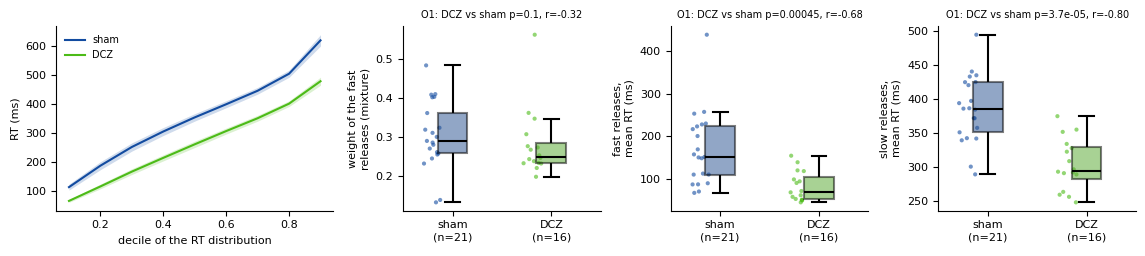

RT deciles (ms), median over sessions:
             0.1    0.2    0.3    0.4    0.5    0.6    0.7    0.8    0.9
injection                                                               
sham       106.0  181.0  253.0  311.0  353.0  398.0  440.0  497.0  605.0
DCZ         63.0  114.0  156.0  210.0  255.0  305.0  347.0  397.0  464.0
DCZ - sham (ms): [-43.0, -66.0, -97.0, -101.0, -98.0, -93.0, -93.0, -100.0, -141.0]
DCZ / sham     : [0.59, 0.63, 0.62, 0.67, 0.72, 0.77, 0.79, 0.8, 0.77]
DCZ vs sham p per decile: [8.2e-05, 0.000173, 0.000153, 5.5e-05, 3.3e-05, 2.2e-05, 1.1e-05, 8e-06, 1.1e-05]


In [52]:
# shift function: deciles of the RT distribution per session
deciles = np.round(np.arange(0.1, 0.91, 0.1), 1)
rt_deciles = dcz_trials.groupby('session')['rt_ms'].quantile(deciles).unstack().join(dcz_sessions['injection'])
decile_long = rt_deciles.reset_index().melt(id_vars=['session', 'injection'], var_name='decile', value_name='rt_ms')

# two-component Gaussian mixture of log RT per session: weight and mean of the fast and of the slow releases
mixture = {}
for session, session_trials in dcz_trials.groupby('session'):
    gm = GaussianMixture(2, n_init=5, random_state=0).fit(session_trials[['log_rt']].values)
    fast, slow = np.argsort(gm.means_.ravel())
    mixture[session] = {'fast_weight': gm.weights_[fast], 'fast_mean_ms': np.exp(gm.means_[fast, 0]), 'slow_mean_ms': np.exp(gm.means_[slow, 0])}
dcz_sessions = dcz_sessions.drop(columns=['fast_weight', 'fast_mean_ms', 'slow_mean_ms'], errors='ignore').join(pd.DataFrame(mixture).T.astype(float))

fig, axs = plt.subplots(1, 4, figsize=(11.5, 2.6), gridspec_kw={'width_ratios': [1.4, 1, 1, 1]})
ax = axs[0]
plot_condition_lines(ax, decile_long, 'decile', 'rt_ms')
ax.set_xlabel('decile of the RT distribution')
ax.set_ylabel('RT (ms)')
ax.legend(frameon=False, fontsize=7)
plot_original_panel(axs[1], dcz_sessions, 'fast_weight', 'weight of the fast\nreleases (mixture)', 'O1')
plot_original_panel(axs[2], dcz_sessions, 'fast_mean_ms', 'fast releases,\nmean RT (ms)', 'O1', '{:.0f}')
plot_original_panel(axs[3], dcz_sessions, 'slow_mean_ms', 'slow releases,\nmean RT (ms)', 'O1', '{:.0f}')
plt.tight_layout()
plt.savefig('figs/yu_dcz_O1_rt_distribution.svg', dpi=300)
plt.show()

decile_medians = rt_deciles.groupby('injection').median().loc[DCZ_ORDER]
decile_p = [stats.mannwhitneyu(*(rt_deciles.loc[rt_deciles.injection == injection, d] for injection in ('DCZ', 'sham'))).pvalue for d in deciles]
print('RT deciles (ms), median over sessions:')
print(decile_medians.round(0).to_string())
print('DCZ - sham (ms):', (decile_medians.loc['DCZ'] - decile_medians.loc['sham']).round(0).tolist())
print('DCZ / sham     :', (decile_medians.loc['DCZ'] / decile_medians.loc['sham']).round(2).tolist())
print('DCZ vs sham p per decile:', np.round(decile_p, 6).tolist())

### O5. Is the DCZ effect stable over the months of injections?

Repeated chemogenetic activation could lose efficacy over time (tolerance), or its behavioral effect could grow (sensitization). For each DCZ session, the effect is measured against the sham sessions within ±7 days, and its trend over the successive DCZ sessions is tested.

log_rt_effect: effect present (Wilcoxon vs 0) p=6.1e-05, same sign in 15/15 DCZ sessions, trend over sessions rho=+0.03 (p=0.92)
late_release_effect: effect present (Wilcoxon vs 0) p=0.00012, same sign in 14/15 DCZ sessions, trend over sessions rho=-0.28 (p=0.31)


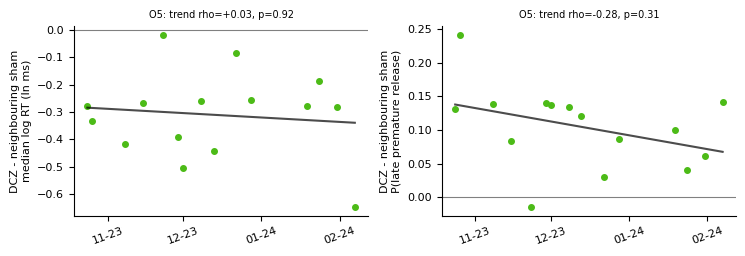

In [53]:
neighbour_effects = []
for session, row in dcz_sessions[dcz_sessions.injection == 'DCZ'].sort_values('date').iterrows():
    neighbours = dcz_sessions[(dcz_sessions.injection == 'sham') & ((dcz_sessions['date'] - row['date']).abs() <= pd.Timedelta(days=7))]
    if len(neighbours) > 0:
        neighbour_effects.append({'session': session, 'date': row['date'],
                                  'log_rt_effect': row['log_rt'] - neighbours['log_rt'].mean(),
                                  'late_release_effect': row['late_release_hazard'] - neighbours['late_release_hazard'].mean()})
neighbour_effects = pd.DataFrame(neighbour_effects)
neighbour_effects['days'] = (neighbour_effects['date'] - neighbour_effects['date'].min()).dt.days

fig, axs = plt.subplots(1, 2, figsize=(7.5, 2.6))
for ax, (measure, ylabel) in zip(axs, {'log_rt_effect': 'DCZ - neighbouring sham\nmedian log RT (ln ms)',
                                        'late_release_effect': 'DCZ - neighbouring sham\nP(late premature release)'}.items()):
    ax.plot(neighbour_effects['date'], neighbour_effects[measure], 'o', color=INJECTION_COLORS['DCZ'], markersize=4)
    fit = np.polyfit(neighbour_effects['days'], neighbour_effects[measure], 1)
    ax.plot(neighbour_effects['date'], np.polyval(fit, neighbour_effects['days']), color='black', alpha=0.7)
    ax.axhline(0, color='grey', linewidth=0.8)
    rho, p_trend = stats.spearmanr(neighbour_effects['days'], neighbour_effects[measure])
    p_present = stats.wilcoxon(neighbour_effects[measure]).pvalue
    n_consistent = int((np.sign(neighbour_effects[measure]) == np.sign(neighbour_effects[measure].median())).sum())
    ax.set_title(f'O5: trend rho={rho:+.2f}, p={p_trend:.2g}', fontsize=7)
    ax.set_ylabel(ylabel)
    format_date_axis(ax)
    ORIGINAL_RESULTS[('O5', f'{measure} trend')] = {'test': 'trend over DCZ sessions, Spearman (rho)', 'effect': rho, 'p': p_trend,
                                                   'values': f'median effect {neighbour_effects[measure].median():+.3f}; same sign in {n_consistent}/{len(neighbour_effects)} DCZ sessions'}
    print(f'{measure}: effect present (Wilcoxon vs 0) p={p_present:.2g}, same sign in {n_consistent}/{len(neighbour_effects)} DCZ sessions, '
          f'trend over sessions rho={rho:+.2f} (p={p_trend:.2g})')
plt.tight_layout()
plt.savefig('figs/yu_dcz_O5_stability.svg', dpi=300)
plt.show()

### Hypotheses and conclusions: execution

Data: 21 sham and 16 DCZ sessions (Nov 2023 – Feb 2024), ~550 completed trials each (session ends after a fixed number of rewards).

- **H1. DCZ shortens the RT.** Increasing NA makes monkeys execute trials faster (Kaduk et al., 2023); lowering NA with clonidine reduces energization (Jahn et al., 2018; Borderies et al., 2020).
  Result: median RT 353 ms (sham) → 255 ms (DCZ), p = 3×10⁻⁵, r = −0.81, q < 0.001, adjusted OLS p = 5×10⁻⁸. **Supported.**
- **H2. Motor execution is unchanged** (cognitive vs motor dissociation, manuscript discussion).
  Result: movement time 227 vs 230 ms, p = 0.79. **Supported:** only the lever release is faster, not the movement to the target.
- **The four intervals of a trial** (median of the session medians, sham → DCZ):
  - lever available → first lever touch: 178 → 166 ms (p = 0.94)
  - lever validation → lever release (RT): 353 → 255 ms (p = 3×10⁻⁵)
  - lever release → target touch: 227 → 230 ms (p = 0.79)
  - target validation → target release: 488 → 416 ms (p = 0.02, r = −0.46; adjusted OLS p = 0.10)

  Only the releases after a validation are faster: the lever release clearly, the target release weakly. Starting the trial and moving to the target are unchanged.
- **RT across the session** (10 bins of trials): DCZ is faster in every tenth of the session (~185-225 vs ~260-340 ms, p < 0.05 in all bins); the difference is largest at the start.
- **Trial length** (trial start → end, mean per session): 6.5 vs 6.4 s (p = 0.82). The faster releases are compensated by the extra lever re-holds (level 2).
- **O1. DCZ accelerates the whole release process, rather than adding anticipatory guesses.**
  Result: every decile of the RT distribution is shorter under DCZ (−43 ms at the 10th, −141 ms at the 90th percentile, all p < 2×10⁻⁴). In a two-component mixture, the share of fast releases is unchanged (0.29 vs 0.25, p = 0.10), but both fast (152 → 71 ms) and slow, cue-reactive releases (386 → 295 ms) are earlier (q ≤ 0.001). **Supported.**
- **O5. The effect is stable over the months of injections.**
  Result: RT is shorter than in the neighbouring sham sessions (±7 days) in 15/15 DCZ sessions, with no trend over time (ρ = +0.03, p = 0.92). **Supported:** no tolerance or sensitization.

**Conclusion:** DCZ strongly and reproducibly speeds up the lever release (~100 ms, in every DCZ session), across the whole RT distribution, and weakly the target release. It does not change trial initiation, the arm movement or the trial length.

## 2. Engagement / motivation level

### Number of events and false touches per trial

Mean per completed trial, per session. Extracted from the raw events by `popy.behavior_data_tools.get_behavior_yuri()` (event codes: `data/code_LUV_task.txt`):
- number of events: all events between trial start (100) and trial end (101), as a measure of vigour
- early lever release: lever touch (61) released before lever validation (63), i.e. not followed by validation (62)
- late lever touch: lever touch (61) after lever validation (62)
- early target release: target touch (121/122/123) released before target validation (124), i.e. not followed by validation (125)
- late target touch, rewarded / not rewarded: target touch after target validation (131-136, during END 141-143, or 121/122/123 after the 125), mean per rewarded / not rewarded trial. The outcome is taken from the 65 code of the trial (for the END touches, this is the feedback before the touch), because the codes after no reward (134-136) are never sent in this data and 131-133 are sent after both outcomes.

n_events, mean per trial (mean ± std over sessions):
             mean    std
injection               
sham       19.900  0.885
DCZ        21.365  0.993
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
                 n_events
group_1 group_2          
sham    DCZ        0.0001


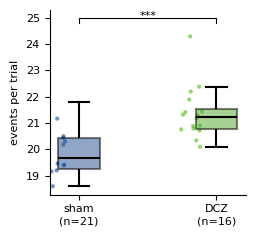

n_early_lever_release, mean per trial (mean ± std over sessions):
            mean    std
injection              
sham       0.687  0.206
DCZ        0.956  0.167
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
                 n_early_lever_release
group_1 group_2                       
sham    DCZ                     0.0002


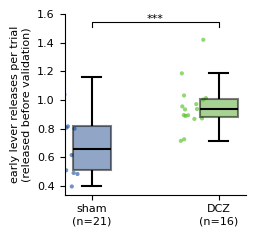

n_late_lever_touch, mean per trial (mean ± std over sessions):
           mean  std
injection           
sham        0.0  0.0
DCZ         0.0  0.0
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
never occurs, not tested


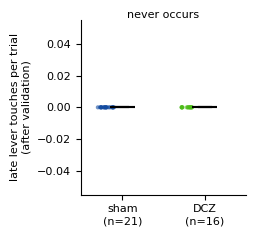

n_early_target_release, mean per trial (mean ± std over sessions):
            mean    std
injection              
sham       0.381  0.119
DCZ        0.499  0.162
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
                 n_early_target_release
group_1 group_2                        
sham    DCZ                      0.0224


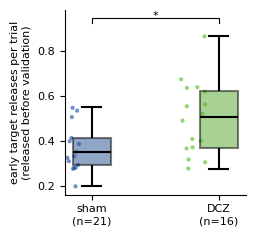

In [54]:
INJECTIONS_5 = INJECTIONS
sessions_5 = sessions[sessions.injection.isin(INJECTIONS_5)]

# one figure per measure
measures_5 = {
    'n_events': ('events per trial', 'figs/yu_events_per_trial.svg'),
    'n_early_lever_release': ('early lever releases per trial\n(released before validation)', 'figs/yu_early_lever_releases.svg'),
    'n_late_lever_touch': ('late lever touches per trial\n(after validation)', 'figs/yu_late_lever_touches.svg'),
    'n_early_target_release': ('early target releases per trial\n(released before validation)', 'figs/yu_early_target_releases.svg'),
}
for measure, (ylabel, fname) in measures_5.items():
    fig, p_holm = compare_injections(sessions_5, {measure: ylabel}, ncols=1, order=INJECTIONS_5)

    # print statistics
    print(f'{measure}, mean per trial (mean ± std over sessions):')
    print(sessions_5.groupby('injection')[measure].agg(['mean', 'std']).loc[INJECTIONS_5].round(3).to_string())
    print('Pairwise Mann-Whitney U tests, Holm-corrected p-values:')
    print(p_holm.round(4).to_string() if not p_holm.empty else 'never occurs, not tested')

    # save as svg, 300 dpi
    plt.savefig(fname, dpi=300)
    plt.show()

## (6) Effects of the chemogenetic activation of the LC/NA→MCC pathway (DCZ)

DCZ activates the DREADD-expressing noradrenergic (LC) neurons that project to the MCC. The hypotheses tested below are listed, with their literature background and the results, in the report at the end of the notebook.

Approach:
- Primary contrast: **DCZ vs sham** (saline injection) sessions. DCZ and sham days alternate within the same weeks (Tue/Thu sham, Wed/Fri DCZ), so they share the period of training and the injection procedure. *None* sessions are shown for reference only: most of them are Mondays after the weekend break, so they differ from the injection days in more than the injection. MISSING sessions are excluded.
- Unit of analysis: the session (one value per session), completed trials only.
- Test: two-sided Mann-Whitney U, effect size: rank-biserial correlation r (r > 0: larger under DCZ). Robustness check: OLS of the session values on DCZ, session date and weekday (sham and DCZ sessions only).
- All DCZ vs sham tests are collected in a summary table with Benjamini-Hochberg FDR correction (q).

In [55]:
# check of the early lever release count: distribution per trial, and cross-check with the lever holds
# extracted from the raw events in get_trial_timing() (holds released before validation)
counts = dcz_trials['n_early_lever_release'].clip(upper=5)
print('share of trials with 0, 1, 2, ... early lever releases (5 = 5 or more):')
print(pd.crosstab(dcz_trials['injection'], counts, normalize='index').loc[INJECTIONS].round(3).to_string())

holds_per_trial = dcz_holds.groupby(['session', 'trial_start_time']).agg(injection=('injection', 'first'),
                                                                         early_release=('validated', lambda v: (~v).sum()))
print('\nmean early lever releases per trial: preprocessed data vs raw lever holds')
print(pd.DataFrame({'preprocessed': dcz_trials.groupby('injection')['n_early_lever_release'].mean(),
                    'raw holds': holds_per_trial.groupby('injection')['early_release'].mean()}).loc[INJECTIONS].round(3).to_string())

share of trials with 0, 1, 2, ... early lever releases (5 = 5 or more):
n_early_lever_release      0      1      2      3      4      5
injection                                                      
sham                   0.710  0.128  0.072  0.038  0.021  0.031
DCZ                    0.602  0.173  0.090  0.058  0.031  0.047



mean early lever releases per trial: preprocessed data vs raw lever holds
           preprocessed  raw holds
injection                         
sham              0.693      0.692
DCZ               0.963      0.962


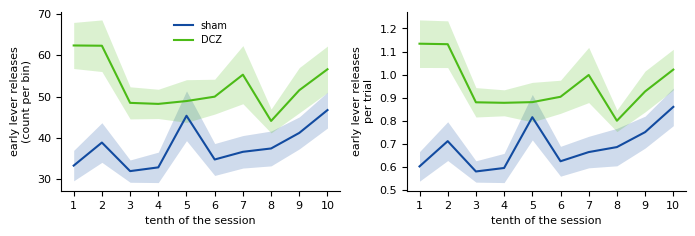

n_early_lever_release, DCZ vs sham p per bin: [0.0, 0.004, 0.002, 0.005, 0.374, 0.014, 0.008, 0.075, 0.197, 0.276]
early_lever_release_per_trial, DCZ vs sham p per bin: [0.0, 0.006, 0.001, 0.004, 0.408, 0.008, 0.003, 0.078, 0.111, 0.276]


In [56]:
# early lever releases across the session: session divided in 10 bins of trials, count and mean per trial per bin
dcz_trials['session_bin'] = np.minimum((dcz_trials['session_fraction'] * 10).astype(int), 9) + 1
session_bins = dcz_trials.groupby(['session', 'session_bin']).agg(
    injection=('injection', 'first'), n_early_lever_release=('n_early_lever_release', 'sum'),
    early_lever_release_per_trial=('n_early_lever_release', 'mean')).reset_index()

fig, axs = plt.subplots(1, 2, figsize=(7, 2.4))
for ax, (measure, ylabel) in zip(axs, {'n_early_lever_release': 'early lever releases\n(count per bin)',
                                       'early_lever_release_per_trial': 'early lever releases\nper trial'}.items()):
    plot_condition_lines(ax, session_bins, 'session_bin', measure)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel('tenth of the session')
    ax.set_ylabel(ylabel)
axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_early_lever_release_over_session.svg', dpi=300)
plt.show()

# DCZ vs sham per bin (Mann-Whitney U over sessions, uncorrected)
for measure in ['n_early_lever_release', 'early_lever_release_per_trial']:
    p_bins = [stats.mannwhitneyu(*(values.loc[values.injection == injection, measure] for injection in ('DCZ', 'sham'))).pvalue
              for _, values in session_bins.groupby('session_bin')]
    print(f'{measure}, DCZ vs sham p per bin:', np.round(p_bins, 3).tolist())

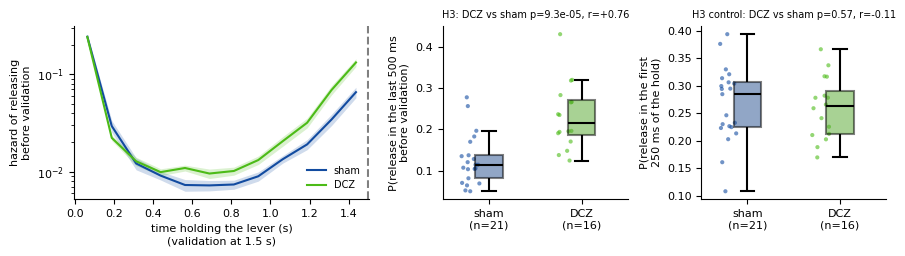

early lever releases per trial (median of sessions): {'sham': 0.659, 'DCZ': 0.937}
            measure  median_sham  median_dcz       r      p  p_adjusted_ols
late_release_hazard       0.1141      0.2152  0.7619 0.0001          0.0000
        slip_hazard       0.2849      0.2626 -0.1131 0.5706          0.8636


In [57]:
# H3: is the faster RT part of an earlier lever release overall (anticipation of the end of the 1.5 s hold)?
# hazard of releasing the lever before validation, in 125 ms bins of holding time, per session
bins = np.arange(0, 1.5 + 1e-9, 0.125)
hazards = pd.DataFrame([{'session': session, 'injection': session_holds['injection'].iloc[0], 'hold_time': start + 0.0625,
                         'hazard': release_hazard(session_holds, start, start + 0.125)}
                        for session, session_holds in dcz_holds.groupby('session') for start in bins[:-1]])

fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), gridspec_kw={'width_ratios': [1.6, 1, 1]})
ax = axs[0]
plot_condition_lines(ax, hazards, 'hold_time', 'hazard')
ax.set_yscale('log')
ax.axvline(1.5, color='grey', linestyle='--')
ax.set_xlabel('time holding the lever (s)\n(validation at 1.5 s)')
ax.set_ylabel('hazard of releasing\nbefore validation')
ax.legend(frameon=False, fontsize=7)
plot_dcz_panel(axs[1], dcz_sessions, 'late_release_hazard', 'P(release in the last 500 ms\nbefore validation)', 'H3')
plot_dcz_panel(axs[2], dcz_sessions, 'slip_hazard', 'P(release in the first\n250 ms of the hold)', 'H3 control')
plt.tight_layout()
plt.savefig('figs/yu_dcz_A_lever_hold.svg', dpi=300)
plt.show()

print('early lever releases per trial (median of sessions):', dcz_sessions.groupby('injection')['early_lever_release'].median().loc[DCZ_ORDER].round(3).to_dict())
print(pd.DataFrame([DCZ_RESULTS[key] for key in [('H3', 'late_release_hazard'), ('H3 control', 'slip_hazard')]]).round(4).to_string(index=False))

### O2. Are the extra premature lever releases a failure of error correction?

The MCC is involved in performance monitoring, so activating its noradrenergic input could impair the correction after a timing error. If so, a premature lever release should more often be followed by another one. Alternatively, DCZ affects only the first attempt to hold the lever in a trial, and the correction after an error is intact.

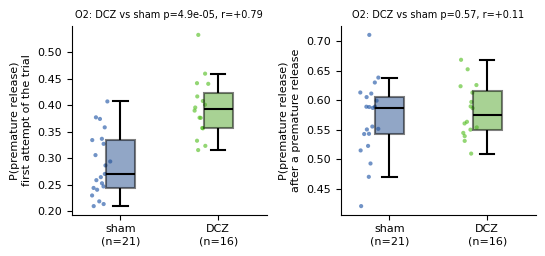

In [58]:
# lever hold attempts in order within each trial (from (6)): premature release on the first attempt, and after a premature release
attempts = dcz_holds.copy()
attempts['attempt'] = attempts.groupby(['session', 'trial_start_time']).cumcount()
attempts['premature'] = (~attempts['validated']).astype(float)
attempts['previous_premature'] = attempts.groupby(['session', 'trial_start_time'])['premature'].shift(1)
dcz_sessions['premature_first_attempt'] = attempts[attempts['attempt'] == 0].groupby('session')['premature'].mean()
dcz_sessions['premature_after_premature'] = attempts[attempts['previous_premature'] == 1].groupby('session')['premature'].mean()

fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6))
plot_original_panel(axs[0], dcz_sessions, 'premature_first_attempt', 'P(premature release)\nfirst attempt of the trial', 'O2')
plot_original_panel(axs[1], dcz_sessions, 'premature_after_premature', 'P(premature release)\nafter a premature release', 'O2')
plt.tight_layout()
plt.savefig('figs/yu_dcz_O2_timing_errors.svg', dpi=300)
plt.show()

### O3. Does DCZ advance the commitment to the choice?

While holding the lever, the monkey sometimes touches a target (codes 111/112/113, the event codes give which target). If the faster release reflects an earlier commitment to the choice, these premature target touches should be more frequent under DCZ, and on switch trials they should more often point to the new target instead of the previous one.

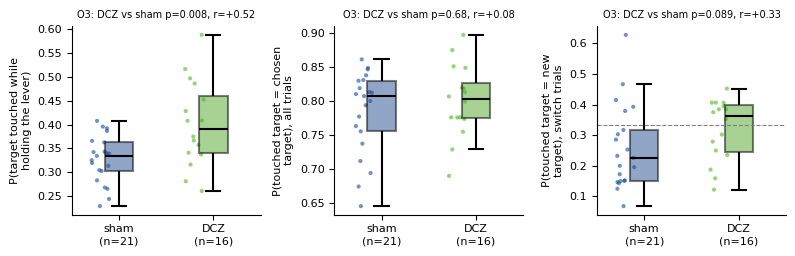

switch trials with an premature target touch per session (median): 42.0


In [59]:
def get_premature_target_touches(session, injection):
    '''Targets touched before the lever validation (111/112/113 -> target 1/2/3), per trial of one session.'''
    raw = load_raw_events(session, injection)
    rows = []
    for trial_events in reformat_behav(raw)['behav_events']:
        codes = trial_events[:, 0].astype(int)
        before_validation = codes[:np.argmax(codes == 62)] if (codes == 62).any() else codes
        touched = before_validation[np.isin(before_validation, [111, 112, 113])] - 110
        rows.append({'session': session, 'trial_start_time': round(trial_events[0, 1], 4),
                     'has_premature_touch': len(touched) > 0, 'last_premature_target': touched[-1] if len(touched) else np.nan})
    return pd.DataFrame(rows)


premature_touches = pd.concat([get_premature_target_touches(session, injection) for session, injection in dcz_sessions['injection'].items()])
touches = dcz_trials.merge(premature_touches, on=['session', 'trial_start_time'], how='left', validate='one_to_one')
with_touch = touches[touches['has_premature_touch']]
dcz_sessions['p_premature_target_touch'] = touches.groupby('session')['has_premature_touch'].mean()
dcz_sessions['touch_is_choice'] = with_touch.groupby('session').apply(lambda t: (t['last_premature_target'] == t['target']).mean())
dcz_sessions['touch_is_new_target'] = with_touch[with_touch['switch'] == 1].groupby('session').apply(lambda t: (t['last_premature_target'] == t['target']).mean())

fig, axs = plt.subplots(1, 3, figsize=(8, 2.6))
plot_original_panel(axs[0], dcz_sessions, 'p_premature_target_touch', 'P(target touched while\nholding the lever)', 'O3')
plot_original_panel(axs[1], dcz_sessions, 'touch_is_choice', 'P(touched target = chosen\ntarget), all trials', 'O3')
plot_original_panel(axs[2], dcz_sessions, 'touch_is_new_target', 'P(touched target = new\ntarget), switch trials', 'O3')
axs[2].axhline(1 / 3, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_O3_early_commitment.svg', dpi=300)
plt.show()
print('switch trials with an premature target touch per session (median):', with_touch[with_touch['switch'] == 1].groupby('session').size().median())

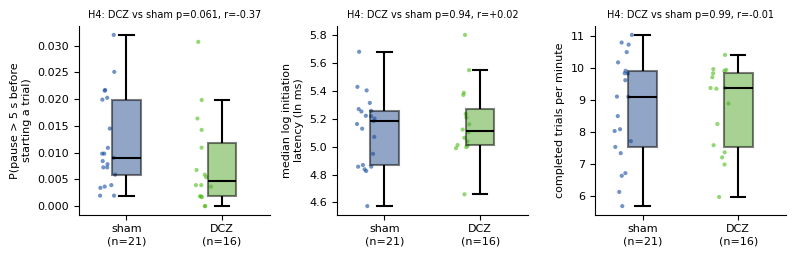

In [60]:
# H4: engagement: pauses before starting a trial (> 5 s), initiation latency, work rate
fig, axs = plt.subplots(1, 3, figsize=(8, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'pause_rate', 'P(pause > 5 s before\nstarting a trial)', 'H4')
plot_dcz_panel(axs[1], dcz_sessions, 'log_initiation', 'median log initiation\nlatency (ln ms)', 'H4')
plot_dcz_panel(axs[2], dcz_sessions, 'trials_per_min', 'completed trials per minute', 'H4')
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_engagement.svg', dpi=300)
plt.show()

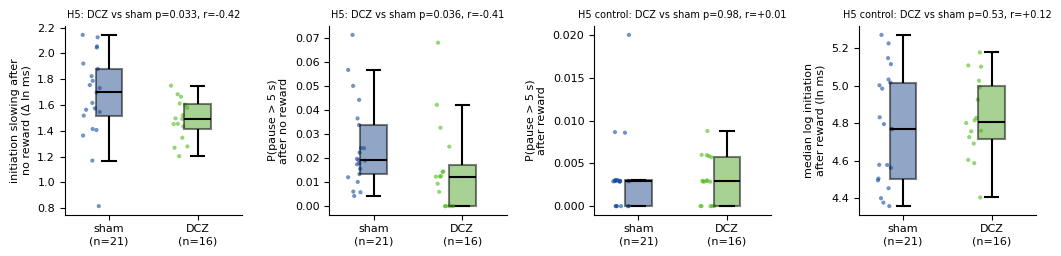

initiation after no reward, when the monkey then stays: sham 628 ms, DCZ 589 ms (p=0.078)
initiation after no reward, when the monkey then switches: sham 634 ms, DCZ 584 ms (p=0.42)


In [61]:
# H5: disengagement after a negative outcome: initiation latency and pauses after a rewarded / not rewarded trial
after = dcz_trials.dropna(subset=['prev_feedback']).groupby(['session', 'prev_feedback']).agg(
    log_initiation=('log_initiation', 'median'), pause=('pause', 'mean')).unstack('prev_feedback')
dcz_sessions['post_loss_slowing'] = after[('log_initiation', 0.0)] - after[('log_initiation', 1.0)]
dcz_sessions['pause_after_loss'] = after[('pause', 0.0)]
dcz_sessions['pause_after_reward'] = after[('pause', 1.0)]
dcz_sessions['log_initiation_after_reward'] = after[('log_initiation', 1.0)]

fig, axs = plt.subplots(1, 4, figsize=(10.5, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'post_loss_slowing', 'initiation slowing after\nno reward (Δ ln ms)', 'H5')
plot_dcz_panel(axs[1], dcz_sessions, 'pause_after_loss', 'P(pause > 5 s)\nafter no reward', 'H5')
plot_dcz_panel(axs[2], dcz_sessions, 'pause_after_reward', 'P(pause > 5 s)\nafter reward', 'H5 control')
plot_dcz_panel(axs[3], dcz_sessions, 'log_initiation_after_reward', 'median log initiation\nafter reward (ln ms)', 'H5 control')
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_post_loss.svg', dpi=300)
plt.show()

# is the faster re-engagement after no reward specific to the trials where the monkey then switches (deliberation)?
after_loss = dcz_trials[dcz_trials['prev_feedback'] == 0].groupby(['session', 'switch']).agg(
    injection=('injection', 'first'), log_initiation=('log_initiation', 'median')).reset_index()
for switch, label in [(0.0, 'stays'), (1.0, 'switches')]:
    DCZ, sham = (after_loss.loc[(after_loss['switch'] == switch) & (after_loss.injection == injection), 'log_initiation'] for injection in ('DCZ', 'sham'))
    print(f'initiation after no reward, when the monkey then {label}: sham {np.exp(sham.median()):.0f} ms, '
          f'DCZ {np.exp(DCZ.median()):.0f} ms (p={stats.mannwhitneyu(DCZ, sham).pvalue:.2g})')

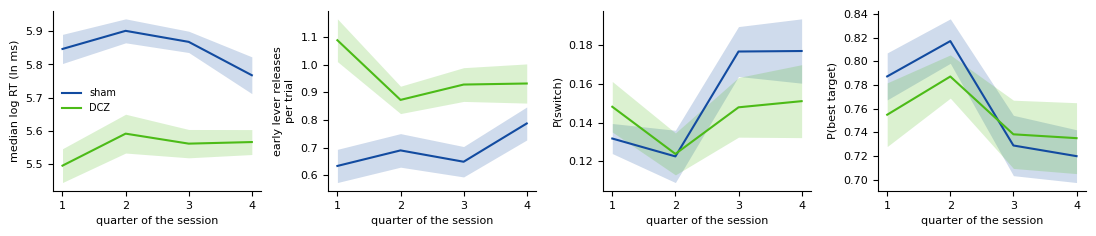

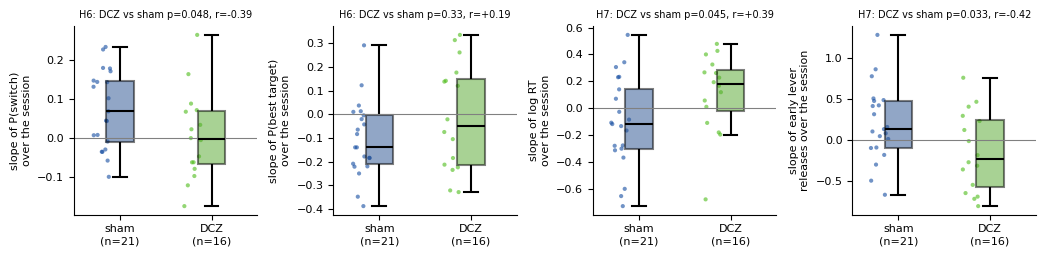

DCZ - sham, log_rt: Q1: -0.403 (p=0.00011) | Q2: -0.339 (p=0.00056) | Q3: -0.258 (p=1.3e-05) | Q4: -0.220 (p=0.008)
DCZ - sham, early_lever_release: Q1: +0.541 (p=0.0002) | Q2: +0.165 (p=0.015) | Q3: +0.333 (p=0.0028) | Q4: +0.161 (p=0.15)
DCZ - sham, switch: Q1: +0.016 (p=0.37) | Q2: +0.017 (p=0.43) | Q3: -0.030 (p=0.18) | Q4: -0.033 (p=0.21)
DCZ - sham, best: Q1: -0.041 (p=0.27) | Q2: -0.040 (p=0.078) | Q3: -0.009 (p=0.93) | Q4: +0.028 (p=0.68)


In [62]:
# H6 (time-on-task) and H7 (time course of the DCZ effect): measures per quarter of the session, and their slope
# over the session (linear fit against the fraction of the session completed)
quarters = dcz_trials.groupby(['session', 'session_quarter']).agg(
    injection=('injection', 'first'), log_rt=('log_rt', 'median'), early_lever_release=('n_early_lever_release', 'mean'),
    switch=('switch', 'mean'), best=('best', 'mean')).reset_index()

fig, axs = plt.subplots(1, 4, figsize=(11, 2.4))
for ax, (measure, ylabel) in zip(axs, {'log_rt': 'median log RT (ln ms)', 'early_lever_release': 'early lever releases\nper trial',
                                       'switch': 'P(switch)', 'best': 'P(best target)'}.items()):
    plot_condition_lines(ax, quarters, 'session_quarter', measure)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xlabel('quarter of the session')
    ax.set_ylabel(ylabel)
axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_time_course.svg', dpi=300)
plt.show()

for measure in ['log_rt', 'early_lever_release', 'switch', 'best']:
    column = {'early_lever_release': 'n_early_lever_release'}.get(measure, measure)
    dcz_sessions[f'{measure}_slope'] = dcz_trials.dropna(subset=[column]).groupby('session').apply(
        lambda session: np.polyfit(session['session_fraction'], session[column].astype(float), 1)[0])

fig, axs = plt.subplots(1, 4, figsize=(10.5, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'switch_slope', 'slope of P(switch)\nover the session', 'H6')
plot_dcz_panel(axs[1], dcz_sessions, 'best_slope', 'slope of P(best target)\nover the session', 'H6')
plot_dcz_panel(axs[2], dcz_sessions, 'log_rt_slope', 'slope of log RT\nover the session', 'H7')
plot_dcz_panel(axs[3], dcz_sessions, 'early_lever_release_slope', 'slope of early lever\nreleases over the session', 'H7')
for ax in axs:
    ax.axhline(0, color='grey', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_slopes.svg', dpi=300)
plt.show()

# DCZ - sham difference of the session medians per quarter
for measure in ['log_rt', 'early_lever_release', 'switch', 'best']:
    rows = []
    for quarter, quarter_values in quarters.groupby('session_quarter'):
        DCZ, sham = (quarter_values.loc[quarter_values.injection == injection, measure] for injection in ('DCZ', 'sham'))
        rows.append(f'Q{quarter}: {DCZ.median() - sham.median():+.3f} (p={stats.mannwhitneyu(DCZ, sham).pvalue:.2g})')
    print(f'DCZ - sham, {measure}: ' + ' | '.join(rows))

### Hypotheses and conclusions: engagement / motivation

**Check of the early lever releases.** The count is correct: it matches the lever holds extracted directly from the raw events (0.69 vs 0.69 per trial in sham, 0.96 vs 0.96 in DCZ). Most trials have none (71 % of sham, 60 % of DCZ trials); the mean of ~1 per trial comes from a tail of trials with many re-holds (3 % of sham and 5 % of DCZ trials have 5 or more). About 28 % of the holds are released within 250 ms (brief touches / slips), the rest are interrupted holds.

- **H3. Earlier lever release overall (temporal anticipation, urgency)** (Murphy et al., 2016; opposite prediction from rodent studies: Robinson et al., 2008; Bari et al., 2020).
  Result: P(release in the last 500 ms of the 1.5 s hold) 0.11 → 0.22 (p = 9×10⁻⁵, q = 0.001); brief slips (first 250 ms) unchanged (0.29 vs 0.26, p = 0.57). Early lever releases per trial 0.69 → 0.96, more events per trial (19.9 → 21.4), more early target releases (0.38 → 0.50). **Supported:** the extra lever presses are re-holds after anticipatory releases.
- **O2. The extra premature releases are not a failure of error correction.**
  Result: P(premature release) on the first attempt of a trial 0.27 → 0.39 (q < 0.001); after a premature release 0.59 vs 0.58 (p = 0.57). **Supported.**
- **O3. DCZ advances the commitment to the choice.**
  Result: target touched while holding the lever in 34 % → 39 % of trials (q = 0.02); the touched target is the chosen one in ~80 % in both; on switch trials it is the new target in 23 % vs 36 % (p = 0.09). **Partially supported.**
- **H4. DCZ increases task engagement** (Gandaux et al., 2025; Aston-Jones & Cohen, 2005).
  Result: pauses > 5 s 0.9 % → 0.5 % of trials (p = 0.06); initiation latency (p = 0.94) and trials per minute (p = 0.99) unchanged. **Not supported** (trend for fewer pauses).
- **H5. DCZ reduces the disengagement after negative outcomes** (Quilodran et al., 2008; Jahn et al., 2018).
  Result: slowing of trial initiation after no reward 1.70 → 1.49 ln units (p = 0.03, q = 0.14); pauses after no reward 1.9 % → 1.2 % (p = 0.04); nothing changes after rewarded trials. **Nominally supported.**
- **H6/H7. Time on task and time course of the effect** (Hopstaken et al., 2015; Nagai et al., 2020).
  Result: the RT difference is largest in the first quarter of the session (−0.40 ln units) and smaller in the last (−0.22, still p = 0.008). Early lever releases: in 10 bins of the session, DCZ is above sham in bins 1-7 (p < 0.02 except bin 5) but not in bins 8-10 (p > 0.07); slope over the session −0.23 (DCZ) vs +0.13 (sham), p = 0.03. Switching rises over the session in sham but not in DCZ (slope p = 0.048).

**Conclusion:** DCZ makes the monkey hold the lever less patiently: more anticipatory releases and re-holds, mostly in the first 70 % of the session, then fading. This is a change in the timing of action rather than more motivation: the general engagement measures (pauses, initiation, work rate) are unchanged, with only a weaker slowing after unrewarded trials (nominal). The early-release effect is therefore not more sustained under DCZ; it declines over the session, consistent with the drug wearing off or with fatigue.

## 3. Cognitive level

### Performance and target selection over the recording period

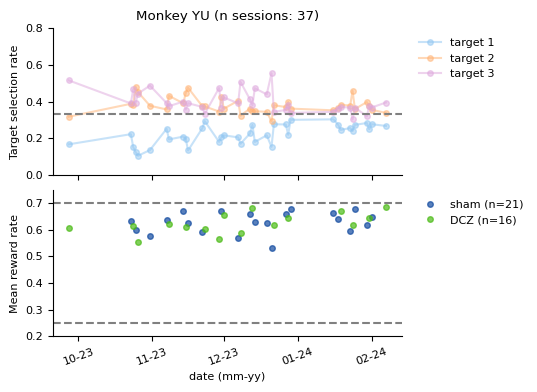

In [63]:
# target selection: all sessions together, mean reward rate: colored by injection type
fig, axs = plt.subplots(2, 1, figsize=(4.5, 4), sharex=True, gridspec_kw={'hspace': 0.1})

# target selection rate
ax = axs[0]
for target in [1, 2, 3]:
    ax.plot(sessions['date'], sessions[f'selection_target_{target}'], marker='o', alpha=.5, label=f'target {target}',
            color=COLORS[f'target_{target}'], markersize=4)
ax.set_title(f'Monkey YU (n sessions: {len(sessions)})')
ax.axhline(1/3, color='gray', linestyle='--')
ax.set_ylim(0, .8)
ax.set_ylabel('Target selection rate')
format_date_axis(ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1, frameon=False)

# mean reward rate
ax = axs[1]
for injection in INJECTIONS:
    session_inj = sessions[sessions.injection == injection]
    ax.plot(session_inj['date'], session_inj['reward_rate'], 'o', color=INJECTION_COLORS[injection], markersize=4, alpha=.7,
            label=f'{injection} (n={len(session_inj)})')
ax.axhline(.25, color='gray', linestyle='--')
ax.axhline(.7, color='gray', linestyle='--')
ax.set_ylim(.20, .75)
ax.set_ylabel('Mean reward rate')
ax.set_xlabel('date (mm-yy)')
format_date_axis(ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1, frameon=False)

# save as png, 300 dpi
fig.savefig('figs/yu_changing_strategy.png', dpi=300, bbox_inches='tight')

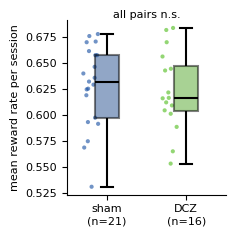

            mean    std
injection              
sham       0.628  0.039
DCZ        0.623  0.038
group_1 group_2  n_1  n_2     U      p  significant  p_holm
   sham     DCZ   21   16 188.5 0.5398        False  0.5398


In [64]:
# mean reward rate per session, per condition
fig, ax = plt.subplots(1, 1, figsize=(2.4, 2.4))
plot_box_with_scatter(sessions, 'reward_rate', ax)
reward_stats = pairwise_tests(sessions, 'reward_rate')
add_significance_bars(ax, reward_stats, sessions['reward_rate'])
ax.set_ylabel('mean reward rate per session')
plt.tight_layout()
plt.savefig('figs/yu_reward_rate_box.svg', dpi=300)
plt.show()

print(sessions.groupby('injection')['reward_rate'].agg(['mean', 'std']).loc[INJECTIONS].round(3).to_string())
print(reward_stats.round(4).to_string(index=False))

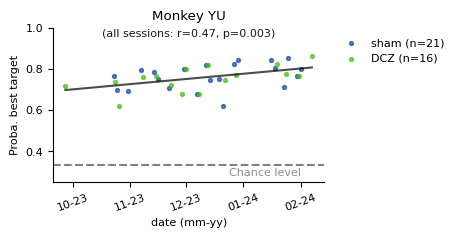

In [65]:
fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

for injection in INJECTIONS:
    session_inj = sessions[sessions.injection == injection]
    ax.scatter(session_inj['date'], session_inj['p_best_target'], color=INJECTION_COLORS[injection], alpha=.7, s=8,
               label=f'{injection} (n={len(session_inj)})')

# fit linear regression line over all sessions, show line and add stats in title
x = sessions['date'].values.astype('datetime64[D]').astype(int)
y = sessions['p_best_target'].values
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
x_fit = np.array([x.min(), x.max()])
ax.plot(x_fit.astype('datetime64[D]'), intercept + slope * x_fit, color='black', alpha=0.7)

ax.set_title('Monkey YU')
p_text = 'p<0.001' if p_value < .001 else f'p={p_value:.3f}'
ax.text(0.5, .93, f'(all sessions: r={r_value:.2f}, {p_text})',
        transform=ax.transAxes, ha='center', va='bottom', color='black', fontsize=8, alpha=0.9)
ax.set_xlabel('date (mm-yy)')
ax.set_ylabel('Proba. best target')
format_date_axis(ax)

ax.axhline(1/3, linestyle='dashed', color='grey')
# print chance level on the grey one
ax.text(0.78, .03, 'Chance level', transform=ax.transAxes, ha='center', va='bottom', color='grey', fontsize=8, alpha=0.9)
ax.set_ylim(.25, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1, frameon=False)

# save as svg, 300 dpi
plt.savefig('figs/yu_proba_best_target_over_time.svg', dpi=300, bbox_inches='tight')

### Number of switches per session

Number of switch trials per session:
	sham: 82.86 ± 26.78 switches per session (n=21)
	DCZ: 78.88 ± 27.50 switches per session (n=16)

Pairwise Mann-Whitney U tests (Holm-corrected):
group_1 group_2  n_1  n_2     U      p  significant  p_holm
   sham     DCZ   21   16 190.0 0.5096        False  0.5096


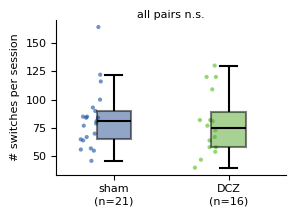

In [66]:
# create boxplot with scatter points for number of switches per session
fig, ax = plt.subplots(1, 1, figsize=(3, 2.2))

plot_box_with_scatter(sessions, 'n_switches', ax)
switch_stats = pairwise_tests(sessions, 'n_switches')
add_significance_bars(ax, switch_stats, sessions['n_switches'])

ax.set_ylabel('# switches per session')
plt.tight_layout()

# print statistics
print('Number of switch trials per session:')
for injection in INJECTIONS:
    values = sessions.loc[sessions.injection == injection, 'n_switches']
    print(f'\t{injection}: {values.mean():.2f} ± {values.std():.2f} switches per session (n={len(values)})')
print('\nPairwise Mann-Whitney U tests (Holm-corrected):')
print(switch_stats.round(4).to_string(index=False))

# save as svg, 300 dpi
plt.savefig('figs/yu_number_of_switches_per_session.svg', dpi=300)

### Learning curves after a block change, weight of past outcomes, model fits, exploration

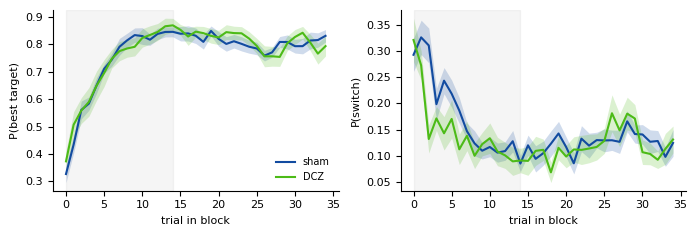

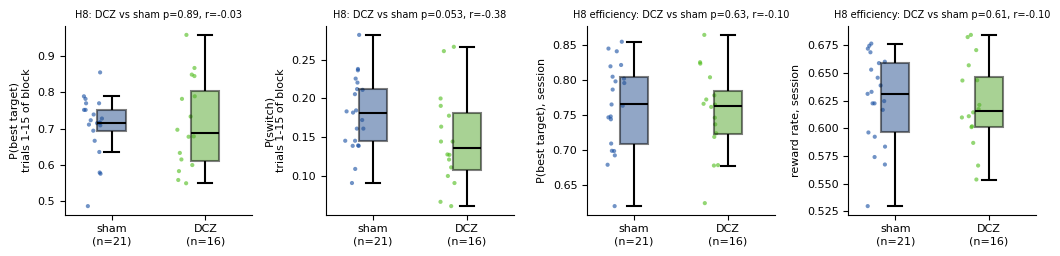

In [67]:
# H8: convergence to the best target after a block change: P(best target) and P(switch) by trial in block
# (first block of the session excluded: no preceding contingency change)
in_block = dcz_trials[dcz_trials['block_id'] > 0]
curves = in_block.groupby(['session', 'trial_id_in_block']).agg(injection=('injection', 'first'), best=('best', 'mean'),
                                                                 switch=('switch', 'mean')).reset_index()
curves = curves[curves['trial_id_in_block'] < 35]
early = in_block[in_block['trial_id_in_block'] < 15].groupby('session')
dcz_sessions['p_best_early_block'] = early['best'].mean()
dcz_sessions['p_switch_early_block'] = early['switch'].mean()

fig, axs = plt.subplots(1, 2, figsize=(7, 2.4))
for ax, (measure, ylabel) in zip(axs, {'best': 'P(best target)', 'switch': 'P(switch)'}.items()):
    plot_condition_lines(ax, curves, 'trial_id_in_block', measure)
    ax.axvspan(0, 14, color='grey', alpha=0.08)
    ax.set_xlabel('trial in block')
    ax.set_ylabel(ylabel)
axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_block_curves.svg', dpi=300)
plt.show()

fig, axs = plt.subplots(1, 4, figsize=(10.5, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'p_best_early_block', 'P(best target)\ntrials 1-15 of block', 'H8')
plot_dcz_panel(axs[1], dcz_sessions, 'p_switch_early_block', 'P(switch)\ntrials 1-15 of block', 'H8')
plot_dcz_panel(axs[2], dcz_sessions, 'p_best', 'P(best target), session', 'H8 efficiency')
plot_dcz_panel(axs[3], dcz_sessions, 'reward_rate', 'reward rate, session', 'H8 efficiency')
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_block_measures.svg', dpi=300)
plt.show()

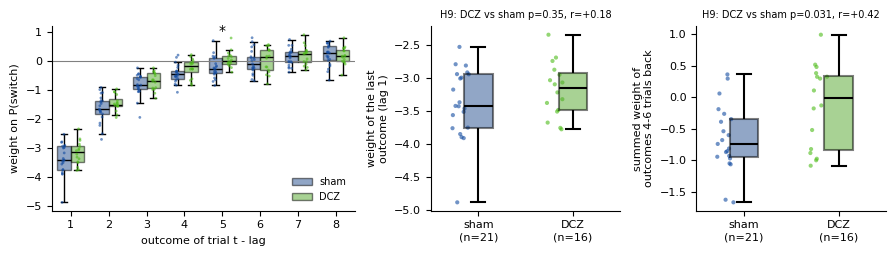

DCZ vs sham per lag (Mann-Whitney U): p = [0.35  0.29  0.434 0.064 0.011 0.657 0.635 0.702] 
  BH q = [0.695 0.695 0.695 0.255 0.091 0.702 0.702 0.702]
             R1    R2    R3    R4    R5    R6
injection                                    
sham      -3.42 -1.66 -0.83 -0.45 -0.26 -0.09
DCZ       -3.16 -1.50 -0.67 -0.18  0.01  0.14


In [77]:
# H9 (part 1): weight of past outcomes on switching, per session. Logistic regression as in the foraging paper (eq. 1,
# scikit-learn with class-balanced weights and the default L2 penalty, which also keeps sessions without any switch
# after some outcome patterns from diverging): P(switch_t) = σ(β0 + β1 R_t-1 + ... + β10 R_t-10)
from sklearn.linear_model import LogisticRegression

N_LAGS = 8
history_weights = {}
for session, session_trials in dcz_trials.groupby('session'):
    design = pd.DataFrame({f'R{lag}': session_trials['feedback'].shift(lag).values for lag in range(1, N_LAGS + 1)})
    design['switch'] = session_trials['switch'].values
    design = design.dropna()
    logistic = LogisticRegression(class_weight='balanced').fit(design.drop(columns='switch'), design['switch'].astype(int))
    history_weights[session] = pd.Series(logistic.coef_[0], index=[f'R{lag}' for lag in range(1, N_LAGS + 1)])
history_weights = pd.DataFrame(history_weights).T.join(dcz_sessions['injection'])
dcz_sessions['older_outcome_weight'] = history_weights[['R4', 'R5', 'R6']].sum(axis=1)   # outcomes 4-6 trials back
dcz_sessions['last_outcome_weight'] = history_weights['R1']

# weights per lag: DCZ vs sham per lag, Benjamini-Hochberg over the lags
lag_p = [stats.mannwhitneyu(*(history_weights.loc[history_weights.injection == injection, f'R{lag}'] for injection in ('DCZ', 'sham'))).pvalue
         for lag in range(1, N_LAGS + 1)]
lag_q = multipletests(lag_p, method='fdr_bh')[1]

fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), gridspec_kw={'width_ratios': [1.6, 1, 1]})
ax = axs[0]
weights_long = history_weights.reset_index(names='session').melt(id_vars=['session', 'injection'], value_vars=[f'R{lag}' for lag in range(1, N_LAGS + 1)],
                                                                 var_name='lag', value_name='weight')
weights_long['lag'] = weights_long['lag'].str[1:].astype(int)
# one pair of boxes (sham, DCZ) per lag, sessions as points, * if DCZ vs sham p < 0.05 (uncorrected)
sns.boxplot(data=weights_long, x='lag', y='weight', hue='injection', hue_order=INJECTIONS, palette=INJECTION_COLORS,
            width=0.7, showfliers=False, ax=ax, boxprops=dict(alpha=0.5, edgecolor='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=1), capprops=dict(color='black', linewidth=1),
            medianprops=dict(color='black', linewidth=1))
sns.stripplot(data=weights_long, x='lag', y='weight', hue='injection', hue_order=INJECTIONS, palette=INJECTION_COLORS,
              dodge=True, size=2, alpha=0.6, jitter=0.1, ax=ax, legend=False)
top = weights_long['weight'].max()
for lag, p in zip(range(1, N_LAGS + 1), lag_p):
    if p < 0.05:
        ax.text(lag - 1, top, '*', ha='center', fontsize=10)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xlabel('outcome of trial t - lag')
ax.set_ylabel('weight on P(switch)')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(frameon=False, fontsize=7, loc='lower right')
plot_dcz_panel(axs[1], dcz_sessions, 'last_outcome_weight', 'weight of the last\noutcome (lag 1)', 'H9')
plot_dcz_panel(axs[2], dcz_sessions, 'older_outcome_weight', 'summed weight of\noutcomes 4-6 trials back', 'H9')
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_history_weights.svg', dpi=300)
plt.show()

print('DCZ vs sham per lag (Mann-Whitney U): p =', np.round(lag_p, 3), '\n  BH q =', np.round(lag_q, 3))
print(history_weights.groupby('injection')[[f'R{lag}' for lag in range(1, 7)]].median().loc[DCZ_ORDER].round(2).to_string())

In [69]:
# model fits per session (maximum likelihood): foraging model and inferential RL model of the foraging paper
# (eq. 4-9). Grid search over all parameters at once, then local refinement (~2 min for all sessions)
import math


def foraging_loglik_grid(choices, rewards, alphas, betas, taus):
    '''Log-likelihood of choices 2..n of the foraging model for every (beta, alpha, tau). V is reset to tau after a switch.'''
    alpha_grid, tau_grid = np.meshgrid(alphas, taus, indexing='ij')
    stay = choices[1:] == choices[:-1]
    values = np.empty((len(stay),) + alpha_grid.shape)
    value = tau_grid + alpha_grid * (rewards[0] - tau_grid)  # first trial: no previous choice, treated as a switch
    for t in range(1, len(choices)):
        values[t - 1] = value
        value = value + alpha_grid * (rewards[t] - value) if stay[t - 1] else tau_grid + alpha_grid * (rewards[t] - tau_grid)
    loglik = np.empty((len(betas),) + alpha_grid.shape)
    for i, beta in enumerate(betas):
        z = beta * (values - tau_grid)  # p(stay) = σ(β(V - τ)), p(each other target) = (1 - p(stay)) / 2
        loglik[i] = np.where(stay[:, None, None], -np.logaddexp(0, -z), -np.logaddexp(0, z) - math.log(2)).sum(0)
    return loglik


def foraging_nll(params, choices, rewards):
    alpha, beta, tau = params
    value, nll = tau + alpha * (rewards[0] - tau), 0.0
    for t in range(1, len(choices)):
        z = beta * (value - tau)
        if choices[t] == choices[t - 1]:
            nll += math.log1p(math.exp(-z)) if z > -30 else -z
            value += alpha * (rewards[t] - value)
        else:
            nll += (math.log1p(math.exp(z)) if z < 30 else z) + math.log(2)
            value = tau + alpha * (rewards[t] - tau)
    return nll


def rl_loglik_grid(choices, rewards, alphas, betas, kappas):
    '''Log-likelihood of choices 2..n of the inferential RL model (softmax with stickiness) for every (alpha, beta, kappa).'''
    n = len(choices)
    q_values, q = np.empty((n, len(alphas), 3)), np.full((len(alphas), 3), 1 / 3)
    for t in range(n):
        q_values[t] = q
        target = np.full(3, 1.0 - rewards[t])  # unchosen targets are updated with the inverse reward
        target[choices[t]] = rewards[t]
        q = q + alphas[:, None] * (target - q)
    q_values = q_values[1:, :, None, :]
    previous = np.eye(3)[choices[:-1]][:, None, None, :]
    chosen = choices[1:][:, None, None, None]
    loglik = np.empty((len(alphas), len(betas), len(kappas)))
    for j, beta in enumerate(betas):
        logits = beta * q_values + kappas[None, None, :, None] * previous
        loglik[:, j, :] = (np.take_along_axis(logits, np.broadcast_to(chosen, logits.shape[:-1] + (1,)), axis=3)[..., 0]
                           - np.logaddexp.reduce(logits, axis=3)).sum(0)
    return loglik


def rl_nll(params, choices, rewards):
    alpha, beta, kappa = params
    q, nll = [1 / 3] * 3, 0.0
    for t in range(len(choices)):
        if t > 0:
            logits = [beta * q[k] + (kappa if k == choices[t - 1] else 0.0) for k in range(3)]
            top = max(logits)
            nll -= logits[choices[t]] - top - math.log(sum(math.exp(logit - top) for logit in logits))
        q = [q[k] + alpha * ((rewards[t] if k == choices[t] else 1.0 - rewards[t]) - q[k]) for k in range(3)]
    return nll


def fit_model(loglik_grid, nll, grids, bounds, choices, rewards, grid_order):
    '''Best grid point, then L-BFGS-B refinement. grid_order: positions of the parameters in the grid axes.'''
    loglik = loglik_grid(choices, rewards, *grids)
    best = np.unravel_index(np.argmax(loglik), loglik.shape)
    start = [grids[i][best[grid_order[i]]] for i in range(3)]
    return optimize.minimize(nll, start, args=(choices, rewards), bounds=bounds, method='L-BFGS-B')


model_fits = {}
for session, session_trials in dcz_trials.groupby('session'):
    choices, rewards = session_trials['target'].astype(int).values - 1, session_trials['feedback'].astype(float).values
    foraging = fit_model(foraging_loglik_grid, foraging_nll,
                         [np.logspace(-2, 0, 20), np.logspace(-0.5, 2, 20), np.linspace(0.02, 0.98, 20)],
                         [(0.005, 1), (0.1, 300), (0.005, 0.995)], choices, rewards, grid_order=[1, 0, 2])
    rl = fit_model(rl_loglik_grid, rl_nll, [np.logspace(-2, 0, 20), np.logspace(-0.5, 2, 20), np.linspace(-2, 6, 17)],
                   [(0.005, 1), (0.1, 300), (-5, 15)], choices, rewards, grid_order=[0, 1, 2])
    n = len(choices) - 1
    model_fits[session] = {'foraging_alpha': foraging.x[0], 'foraging_beta': foraging.x[1], 'foraging_tau': foraging.x[2],
                           'foraging_lpt': np.exp(-foraging.fun / n), 'rl_alpha': rl.x[0], 'rl_beta': rl.x[1],
                           'rl_kappa': rl.x[2], 'rl_lpt': np.exp(-rl.fun / n)}
model_fits = pd.DataFrame(model_fits).T
dcz_sessions = dcz_sessions.drop(columns=model_fits.columns, errors='ignore').join(model_fits)
dcz_sessions['log_foraging_beta'] = np.log(dcz_sessions['foraging_beta'])
dcz_sessions['log_rl_beta'] = np.log(dcz_sessions['rl_beta'])

print('likelihood per trial (median over sessions):')
print(dcz_sessions.groupby('injection')[['foraging_lpt', 'rl_lpt']].median().loc[DCZ_ORDER].round(3).to_string())

/tmp/ipykernel_2619841/2914556326.py:18: RuntimeWarning: invalid value encountered in logaddexp
  loglik[i] = np.where(stay[:, None, None], -np.logaddexp(0, -z), -np.logaddexp(0, z) - math.log(2)).sum(0)
/tmp/ipykernel_2619841/2914556326.py:52: RuntimeWarning: invalid value encountered in reduce
  - np.logaddexp.reduce(logits, axis=3)).sum(0)
/tmp/ipykernel_2619841/2914556326.py:18: RuntimeWarning: invalid value encountered in logaddexp
  loglik[i] = np.where(stay[:, None, None], -np.logaddexp(0, -z), -np.logaddexp(0, z) - math.log(2)).sum(0)
/tmp/ipykernel_2619841/2914556326.py:52: RuntimeWarning: invalid value encountered in reduce
  - np.logaddexp.reduce(logits, axis=3)).sum(0)
/tmp/ipykernel_2619841/2914556326.py:18: RuntimeWarning: invalid value encountered in logaddexp
  loglik[i] = np.where(stay[:, None, None], -np.logaddexp(0, -z), -np.logaddexp(0, z) - math.log(2)).sum(0)
/tmp/ipykernel_2619841/2914556326.py:52: RuntimeWarning: invalid value encountered in reduce
  - np.logadd

likelihood per trial (median over sessions):
           foraging_lpt  rl_lpt
injection                      
sham              0.727   0.691
DCZ               0.728   0.702


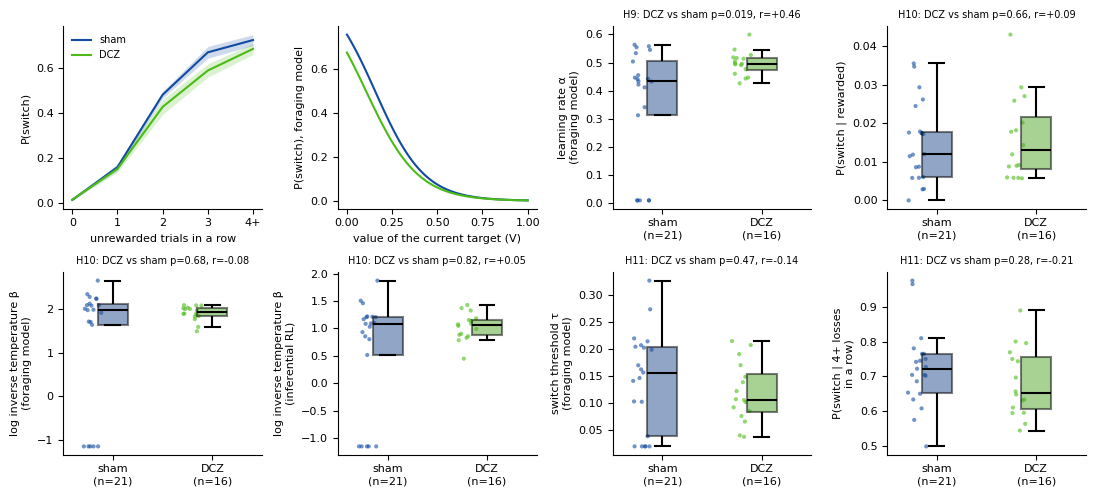

P(switch) by unrewarded trials in a row (median of sessions):
               0      1      2      3      4
injection                                   
sham       0.012  0.152  0.500  0.649  0.722
DCZ        0.013  0.150  0.432  0.618  0.653
rl_alpha: sham 0.438, DCZ 0.568, p=0.078
rl_kappa: sham 2.218, DCZ 2.752, p=0.0034
Spearman correlation of the foraging parameters over sessions:
                   foraging_alpha  log_foraging_beta  foraging_tau
foraging_alpha                1.0              -0.00          0.10
log_foraging_beta            -0.0               1.00          0.66
foraging_tau                  0.1               0.66          1.00


In [70]:
# H9 (part 2): learning rate; H10: decision noise / random (value-free) exploration; H11: persistence (switch threshold)
def consecutive_losses(feedback):
    '''Number of unrewarded trials in a row before each trial.'''
    losses, count = [], 0
    for outcome in feedback:
        losses.append(count)
        count = count + 1 if outcome == 0 else 0
    return losses


dcz_trials['losses_before'] = dcz_trials.groupby('session')['feedback'].transform(lambda feedback: consecutive_losses(feedback.values))
dcz_trials['losses_bin'] = np.minimum(dcz_trials['losses_before'], 4)
loss_curves = dcz_trials.dropna(subset=['switch']).groupby(['session', 'losses_bin']).agg(
    injection=('injection', 'first'), switch=('switch', 'mean')).reset_index()
switch_by_losses = loss_curves.pivot(index='session', columns='losses_bin', values='switch')
dcz_sessions['win_shift'] = switch_by_losses[0]          # switching after a reward: value-free random exploration
dcz_sessions['switch_after_4_losses'] = switch_by_losses[4]

fig, axs = plt.subplots(2, 4, figsize=(11, 5))
ax = axs[0, 0]
plot_condition_lines(ax, loss_curves, 'losses_bin', 'switch')
ax.set_xticks(range(5), ['0', '1', '2', '3', '4+'])
ax.set_xlabel('unrewarded trials in a row')
ax.set_ylabel('P(switch)')
ax.legend(frameon=False, fontsize=7)

# fitted switching function of the foraging model: P(switch) = 1 - σ(β(V - τ)), median parameters per condition
ax = axs[0, 1]
value = np.linspace(0, 1, 101)
for injection in DCZ_ORDER:
    params = dcz_sessions[dcz_sessions.injection == injection][['foraging_beta', 'foraging_tau']].median()
    ax.plot(value, 1 - 1 / (1 + np.exp(-params['foraging_beta'] * (value - params['foraging_tau']))), color=INJECTION_COLORS[injection], label=injection)
ax.set_xlabel('value of the current target (V)')
ax.set_ylabel('P(switch), foraging model')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plot_dcz_panel(axs[0, 2], dcz_sessions, 'foraging_alpha', 'learning rate α\n(foraging model)', 'H9')
plot_dcz_panel(axs[0, 3], dcz_sessions, 'win_shift', 'P(switch | rewarded)', 'H10')
plot_dcz_panel(axs[1, 0], dcz_sessions, 'log_foraging_beta', 'log inverse temperature β\n(foraging model)', 'H10')
plot_dcz_panel(axs[1, 1], dcz_sessions, 'log_rl_beta', 'log inverse temperature β\n(inferential RL)', 'H10')
plot_dcz_panel(axs[1, 2], dcz_sessions, 'foraging_tau', 'switch threshold τ\n(foraging model)', 'H11')
plot_dcz_panel(axs[1, 3], dcz_sessions, 'switch_after_4_losses', 'P(switch | 4+ losses\nin a row)', 'H11')
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_models.svg', dpi=300)
plt.show()

print('P(switch) by unrewarded trials in a row (median of sessions):')
print(switch_by_losses.join(dcz_sessions['injection']).groupby('injection').median().loc[DCZ_ORDER].round(3).to_string())
for measure in ['rl_alpha', 'rl_kappa']:
    result = dcz_test(dcz_sessions, measure)
    DCZ_RESULTS[('H10/H11 RL', measure)] = result
    print(f'{measure}: sham {result["median_sham"]:.3f}, DCZ {result["median_dcz"]:.3f}, p={result["p"]:.2g}')
print('Spearman correlation of the foraging parameters over sessions:')
print(dcz_sessions[['foraging_alpha', 'log_foraging_beta', 'foraging_tau']].corr(method='spearman').round(2).to_string())

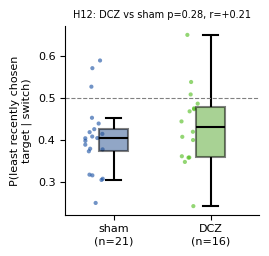

one-sample Wilcoxon vs 0.5: {'sham': 0.0001, 'DCZ': 0.0131}


In [71]:
# H12: directed exploration: when switching, does the monkey go to the less recently chosen of the two other targets?
def p_switch_to_least_recent(targets):
    last_chosen, choices_least_recent = {1: -1, 2: -1, 3: -1}, []
    for t, target in enumerate(targets):
        if t > 0 and target != targets[t - 1]:
            others = [k for k in (1, 2, 3) if k != targets[t - 1]]
            if last_chosen[others[0]] != last_chosen[others[1]]:
                choices_least_recent.append(target == min(others, key=last_chosen.get))
        last_chosen[target] = t
    return np.mean(choices_least_recent)


dcz_sessions['switch_to_least_recent'] = dcz_trials.groupby('session')['target'].apply(lambda targets: p_switch_to_least_recent(targets.astype(int).values))

fig, ax = plt.subplots(1, 1, figsize=(2.8, 2.6))
plot_dcz_panel(ax, dcz_sessions, 'switch_to_least_recent', 'P(least recently chosen\ntarget | switch)', 'H12')
ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_directed_exploration.svg', dpi=300)
plt.show()
print('one-sample Wilcoxon vs 0.5:', {injection: round(stats.wilcoxon(dcz_sessions.loc[dcz_sessions.injection == injection, 'switch_to_least_recent'] - 0.5).pvalue, 4)
                                      for injection in DCZ_ORDER})

### O4. Does DCZ decouple the speed of the response from the decision variables?

Normally the RT carries information about the decision: the release is faster when the current target has a high value, and slower before a switch or a worse choice. A value-independent energization would speed up all releases alike and weaken these relations. To avoid a dilution by anticipatory releases (which cannot carry this information), only the slow, reactive releases (RT ≥ 150 ms) are used. The value of the current target before each trial comes from the foraging model with the session's fitted α and τ (see (6)).

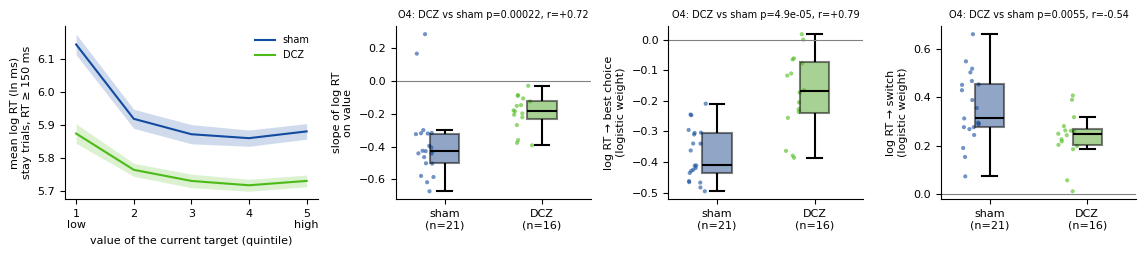

SD of log RT of the reactive releases: sham 0.454, DCZ 0.439 (p=0.022)


In [72]:
def foraging_values(choices, rewards, alpha, tau):
    '''Value of the current target before each trial in the foraging model (NaN for the first trial).'''
    values, value = np.full(len(choices), np.nan), tau + alpha * (rewards[0] - tau)
    for t in range(1, len(choices)):
        values[t] = value
        value = value + alpha * (rewards[t] - value) if choices[t] == choices[t - 1] else tau + alpha * (rewards[t] - tau)
    return values


for session, index in dcz_trials.groupby('session').groups.items():
    session_trials = dcz_trials.loc[index]
    dcz_trials.loc[index, 'value'] = foraging_values(session_trials['target'].values, session_trials['feedback'].values,
                                                     dcz_sessions.loc[session, 'foraging_alpha'], dcz_sessions.loc[session, 'foraging_tau'])

reactive = dcz_trials[dcz_trials['rt_ms'] >= 150].copy()
reactive['z_log_rt'] = reactive.groupby('session')['log_rt'].transform(lambda x: (x - x.mean()) / x.std())
coupling = {}
for session, session_trials in reactive.groupby('session'):
    stay = session_trials[(session_trials['switch'] == 0) & session_trials['value'].notna()]
    with_switch = session_trials.dropna(subset=['switch'])
    coupling[session] = {
        'rt_value_slope': np.polyfit(stay['value'], stay['log_rt'], 1)[0],
        'rt_best_coupling': sm.Logit(with_switch['best'], sm.add_constant(with_switch['z_log_rt'])).fit(disp=0).params['z_log_rt'],
        'rt_switch_coupling': sm.Logit(with_switch['switch'], sm.add_constant(with_switch['z_log_rt'])).fit(disp=0).params['z_log_rt'],
        'reactive_log_rt_sd': session_trials['log_rt'].std()}
dcz_sessions = dcz_sessions.drop(columns=list(next(iter(coupling.values()))), errors='ignore').join(pd.DataFrame(coupling).T)

# log RT by value quintile (stay trials, reactive releases)
stay = reactive[(reactive['switch'] == 0) & reactive['value'].notna()].copy()
stay['value_bin'] = stay.groupby('session')['value'].transform(lambda v: pd.qcut(v, 5, labels=False, duplicates='drop'))
value_curves = stay.groupby(['session', 'value_bin']).agg(injection=('injection', 'first'), log_rt=('log_rt', 'mean')).reset_index()

fig, axs = plt.subplots(1, 4, figsize=(11.5, 2.6), gridspec_kw={'width_ratios': [1.3, 1, 1, 1]})
ax = axs[0]
plot_condition_lines(ax, value_curves, 'value_bin', 'log_rt')
ax.set_xticks(range(5), ['1\nlow', '2', '3', '4', '5\nhigh'])
ax.set_xlabel('value of the current target (quintile)')
ax.set_ylabel('mean log RT (ln ms)\nstay trials, RT ≥ 150 ms')
ax.legend(frameon=False, fontsize=7)
plot_original_panel(axs[1], dcz_sessions, 'rt_value_slope', 'slope of log RT\non value', 'O4')
plot_original_panel(axs[2], dcz_sessions, 'rt_best_coupling', 'log RT → best choice\n(logistic weight)', 'O4')
plot_original_panel(axs[3], dcz_sessions, 'rt_switch_coupling', 'log RT → switch\n(logistic weight)', 'O4')
for ax in axs[1:]:
    ax.axhline(0, color='grey', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_O4_vigor_decoupling.svg', dpi=300)
plt.show()

# control: a weaker relation could also come from a compressed RT range under DCZ
result = dcz_test(dcz_sessions, 'reactive_log_rt_sd')
print(f'SD of log RT of the reactive releases: sham {result["median_sham"]:.3f}, DCZ {result["median_dcz"]:.3f} (p={result["p"]:.2g})')

### Hypotheses and conclusions: cognitive

- **Performance.** Reward rate (0.63 vs 0.62, p = 0.61), P(best target) (0.77 vs 0.76, p = 0.64) and the number of switches per session (83 vs 79, p = 0.51) are unchanged. Performance is stable over the recording period.
- **H8. Faster convergence to the best target after a block change** (manuscript discussion; Bouret & Sara, 2005; Yu & Dayan, 2005).
  Result: in the first 15 trials of a block, P(best target) 0.72 vs 0.69 (p = 0.89), P(switch) 0.18 → 0.14 (p = 0.053). **Not supported** (trend for less switching early in the block).
- **H9. More weight on recent outcomes** (Nassar et al., 2012; regression as in Lau & Glimcher, 2005).
  Result: the weight of the last outcome is unchanged (p = 0.49); the summed weight of outcomes 4-6 trials back is smaller under DCZ (−0.83 → −0.11, p = 0.04, q = 0.14); foraging-model learning rate α 0.43 → 0.50 (p = 0.02, q = 0.14). **Partially supported:** older outcomes are forgotten faster.
- **H10. Change in decision noise / random exploration** (Tervo et al., 2014; Jahn et al., 2018; Warren et al., 2017; Dubois et al., 2021).
  Result: switching after a reward 1.2 % vs 1.3 % (p = 0.66); inverse temperature unchanged in both models (p ≥ 0.68). **Not supported.**
- **H11. Change in persistence (switch threshold).**
  Result: foraging threshold τ 0.16 → 0.11 (p = 0.47); P(switch | 4+ losses in a row) 0.72 → 0.65 (p = 0.28); RL stickiness κ 2.2 → 2.8 (p = 0.003, q = 0.03). **Partially supported:** more stickiness in the RL model only.
- **H12. Directed exploration unchanged** (Warren et al., 2017; Wilson et al., 2014).
  Result: P(switching to the less recently chosen target) 0.40 vs 0.43 (p = 0.28). **Supported.**
- **O4. DCZ decouples the speed of the response from the decision variables.**
  Result (reactive releases, RT ≥ 150 ms): the slope of log RT on the value of the current target goes from −0.43 to −0.18 (q < 0.001); the logistic weight of log RT on choosing the best target from −0.41 to −0.17 (q < 0.001), on switching from +0.31 to +0.25 (q = 0.01). The SD of the reactive log RT is only slightly smaller (0.45 vs 0.44). **Supported.**

**Conclusion:** the choices themselves change little under DCZ: performance, learning after block changes and exploration are unchanged, with only weak signs of more persistence (stickiness, fewer early-block switches) and a shorter outcome memory. The clearest effect at this level is that the RT no longer tracks the value of the choice (O4): DCZ adds a drive to act that does not depend on value.

## Other: carry-over to the next day

### O6. Does the DCZ effect carry over to the next day?

If the activation of the pathway had lasting (e.g. plasticity-related) consequences, sham sessions on the day after a DCZ session would differ from the other sham sessions (mostly Tuesdays, after a Monday without injection).

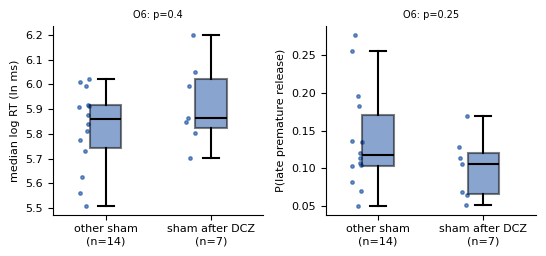

weekdays, sham after DCZ: {'Thursday': 5, 'Wednesday': 1, 'Friday': 1} | other sham: {'Tuesday': 8, 'Thursday': 3, 'Wednesday': 2, 'Monday': 1}


In [73]:
by_date = dcz_sessions.sort_values('date')
previous_day = by_date['injection'].shift(1).where(by_date['date'].diff().dt.days == 1)  # condition of the previous day, if consecutive
sham_next_day = by_date.assign(previous=np.where(previous_day == 'DCZ', 'DCZ', 'other'))[by_date.injection == 'sham']

fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6))
for ax, (measure, ylabel) in zip(axs, {'log_rt': 'median log RT (ln ms)', 'late_release_hazard': 'P(late premature release)'}.items()):
    groups = [sham_next_day.loc[sham_next_day.previous == previous, measure] for previous in ('other', 'DCZ')]
    ax.boxplot(groups, positions=[0, 1], widths=0.3, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=INJECTION_COLORS['sham'], alpha=0.5, edgecolor='black', linewidth=1.5),
               whiskerprops=dict(color='black', linewidth=1.5), capprops=dict(color='black', linewidth=1.5),
               medianprops=dict(color='black', linewidth=1.5))
    for i, values in enumerate(groups):
        ax.scatter(i - 0.2 + np.random.default_rng(i).uniform(-0.05, 0.05, len(values)), values, color=INJECTION_COLORS['sham'], s=6, alpha=0.6)
    p = stats.mannwhitneyu(groups[1], groups[0]).pvalue
    ax.set_xticks([0, 1], [f'other sham\n(n={len(groups[0])})', f'sham after DCZ\n(n={len(groups[1])})'])
    ax.set_ylabel(ylabel)
    ax.set_title(f'O6: p={p:.2g}', fontsize=7)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ORIGINAL_RESULTS[('O6', measure)] = {'test': 'sham after DCZ vs other sham, Mann-Whitney U', 'effect': np.nan, 'p': p,
                                         'values': f'other {groups[0].median():.3g} → after DCZ {groups[1].median():.3g}'}
plt.tight_layout()
plt.savefig('figs/yu_dcz_O6_carryover.svg', dpi=300)
plt.show()
print('weekdays, sham after DCZ:', sham_next_day[sham_next_day.previous == 'DCZ']['date'].dt.day_name().value_counts().to_dict(),
      '| other sham:', sham_next_day[sham_next_day.previous == 'other']['date'].dt.day_name().value_counts().to_dict())

## Summary of the DCZ vs sham tests

Hypotheses H1-H12 (from the literature and the manuscript discussion), Benjamini-Hochberg FDR over all of them:

In [74]:
# all DCZ vs sham tests, Benjamini-Hochberg FDR over all of them
summary = pd.DataFrame([{'hypothesis': hypothesis, **result} for (hypothesis, _), result in DCZ_RESULTS.items()])
summary['q_fdr'] = multipletests(summary['p'], method='fdr_bh')[1]
summary = summary[['hypothesis', 'measure', 'median_sham', 'median_dcz', 'r', 'p', 'q_fdr', 'p_adjusted_ols']]
summary.style.format({column: '{:.3g}' for column in summary.columns[2:]}).apply(
    lambda row: ['font-weight: bold' if row['q_fdr'] < 0.05 else '' for _ in row], axis=1)

,hypothesis,measure,median_sham,median_dcz,r,p,q_fdr,p_adjusted_ols
0,H1,log_rt,5.87,5.54,-0.81,3.27e-05,0.00098,4.94e-08
1,H2,log_mt,5.42,5.44,0.0536,0.794,0.944,0.818
2,H3,late_release_hazard,0.114,0.215,0.762,9.28e-05,0.00139,7.52e-06
3,H3 control,slip_hazard,0.285,0.263,-0.113,0.571,0.848,0.864
4,H4,pause_rate,0.00903,0.00467,-0.366,0.0613,0.153,0.125
5,H4,log_initiation,5.18,5.11,0.0179,0.939,0.988,0.597
6,H4,trials_per_min,9.1,9.36,-0.00595,0.988,0.988,0.49
7,H5,post_loss_slowing,1.7,1.49,-0.417,0.0331,0.144,0.0452
8,H5,pause_after_loss,0.0192,0.0123,-0.411,0.0355,0.144,0.114
9,H5 control,pause_after_reward,0.00292,0.00291,0.00893,0.975,0.988,0.658


Exploratory hypotheses O1-O6 (formulated after seeing the results of H1-H12), separate FDR family:

In [75]:
# tests of (7), Benjamini-Hochberg FDR within this exploratory family
original_summary = pd.DataFrame([{'hypothesis': hypothesis, 'measure': measure, **result} for (hypothesis, measure), result in ORIGINAL_RESULTS.items()])
original_summary['q_fdr'] = multipletests(original_summary['p'], method='fdr_bh')[1]
original_summary = original_summary[['hypothesis', 'measure', 'test', 'values', 'effect', 'p', 'q_fdr']]
original_summary.style.format({'effect': '{:+.2f}', 'p': '{:.2g}', 'q_fdr': '{:.2g}'}, na_rep='').apply(
    lambda row: ['font-weight: bold' if row['q_fdr'] < 0.05 else '' for _ in row], axis=1)

,hypothesis,measure,test,values,effect,p,q_fdr
0,O1,fast_weight,"DCZ vs sham, Mann-Whitney U (r)",sham 0.289 → DCZ 0.249,-0.32,0.1,0.17
1,O1,fast_mean_ms,"DCZ vs sham, Mann-Whitney U (r)",sham 152 → DCZ 71,-0.68,0.00045,0.0013
2,O1,slow_mean_ms,"DCZ vs sham, Mann-Whitney U (r)",sham 386 → DCZ 295,-0.80,3.7e-05,0.00024
3,O5,log_rt_effect trend,"trend over DCZ sessions, Spearman (rho)",median effect -0.280; same sign in 15/15 DCZ sessions,+0.03,0.92,0.92
4,O5,late_release_effect trend,"trend over DCZ sessions, Spearman (rho)",median effect +0.121; same sign in 14/15 DCZ sessions,-0.28,0.31,0.43
5,O2,premature_first_attempt,"DCZ vs sham, Mann-Whitney U (r)",sham 0.271 → DCZ 0.393,+0.79,4.9e-05,0.00024
6,O2,premature_after_premature,"DCZ vs sham, Mann-Whitney U (r)",sham 0.587 → DCZ 0.575,+0.11,0.57,0.66
7,O3,p_premature_target_touch,"DCZ vs sham, Mann-Whitney U (r)",sham 0.335 → DCZ 0.391,+0.52,0.008,0.017
8,O3,touch_is_choice,"DCZ vs sham, Mann-Whitney U (r)",sham 0.807 → DCZ 0.803,+0.08,0.68,0.73
9,O3,touch_is_new_target,"DCZ vs sham, Mann-Whitney U (r)",sham 0.226 → DCZ 0.364,+0.33,0.089,0.17


### Sources

- Aston-Jones & Cohen (2005). An integrative theory of locus coeruleus-norepinephrine function: adaptive gain and optimal performance. *Annu Rev Neurosci*.
- Bari et al. (2020). Differential attentional control mechanisms by two distinct noradrenergic coeruleo-frontal cortical pathways. *PNAS* 117:29080-29089.
- Borderies, Bornert, Gilardeau & Bouret (2020). Pharmacological evidence for the implication of noradrenaline in effort. *PLoS Biol*, doi:10.1371/journal.pbio.3000793.
- Bouret & Sara (2005). Network reset: a simplified overarching theory of locus coeruleus noradrenaline function. *Trends Neurosci* 28:574-582, doi:10.1016/j.tins.2005.09.002.
- Dubois et al. (2021). Human complex exploration strategies are enriched by noradrenaline-modulated heuristics. *eLife* 10:e59907.
- Gandaux et al. (2025). *Curr Biol* (MCC→dlPFC pathway activation with DREADDs increases engagement in a foraging task).
- Hopstaken et al. (2015). A multifaceted investigation of the link between mental fatigue and task disengagement. *Psychophysiology* 52:305-315, doi:10.1111/psyp.12339.
- Jahn et al. (2018). Dual contributions of noradrenaline to behavioural flexibility and motivation. *Psychopharmacology* 235:2687-2702, doi:10.1007/s00213-018-4963-z.
- Jepma & Nieuwenhuis (2011). Pupil diameter predicts changes in the exploration-exploitation trade-off: evidence for the adaptive gain theory. *J Cogn Neurosci*.
- Kaduk et al. (2023), as cited in the manuscript discussion (not checked here).
- Lau & Glimcher (2005). Dynamic response-by-response models of matching behavior in rhesus monkeys. *J Exp Anal Behav* 84:555-579.
- Murphy, Boonstra & Nieuwenhuis (2016). Global gain modulation generates time-dependent urgency during perceptual choice in humans. *Nat Commun* 7:13526, doi:10.1038/ncomms13526.
- Nagai et al. (2020). Deschloroclozapine, a potent and selective chemogenetic actuator enables rapid neuronal and behavioral modulations in mice and monkeys. *Nat Neurosci* 23:1157-1167, doi:10.1038/s41593-020-0661-3.
- Nassar et al. (2012). Rational regulation of learning dynamics by pupil-linked arousal systems. *Nat Neurosci* 15:1040-1046, doi:10.1038/nn.3130.
- Quilodran, Rothé & Procyk (2008). Behavioral shifts and action valuation in the anterior cingulate cortex. *Neuron* 57:314-325, doi:10.1016/j.neuron.2007.11.031.
- Robinson et al. (2008). Similar effects of the selective noradrenaline reuptake inhibitor atomoxetine on three distinct forms of impulsivity in the rat. *Neuropsychopharmacology*.
- Tervo et al. (2014). Behavioral variability through stochastic choice and its gating by anterior cingulate cortex. *Cell*.
- Ungvárszki et al. (2025). Neural dynamics reveal foraging-like computations in the frontal cortex. *bioRxiv*, doi:10.1101/2025.09.29.679289.
- Varazzani, San-Galli, Gilardeau & Bouret (2015). Noradrenaline and dopamine neurons in the reward/effort trade-off: a direct electrophysiological comparison in behaving monkeys. *J Neurosci* 35:7866-7877, doi:10.1523/JNEUROSCI.0454-15.2015.
- Warren et al. (2017). The effect of atomoxetine on random and directed exploration in humans. *PLoS ONE*, doi:10.1371/journal.pone.0176034.
- Wilson et al. (2014). Humans use directed and random exploration to solve the explore-exploit dilemma. *J Exp Psychol Gen* 143:2074-2081, doi:10.1037/a0038199.
- Yu & Dayan (2005). Uncertainty, neuromodulation, and attention. *Neuron* 46:681-692.